# Predicting Representational Geometry — a minimal demonstration

**The object.** Everything here is a factorization of a **log-conditional** $L[\theta,x]=\log p(x\mid\theta)$:
$$L[\theta,x]\;\approx\;\text{embedding}[\theta,\cdot]\;\cdot\;\text{decoder}[\cdot,x].$$
Read it as a basis expansion: the **decoder** rows are **basis functions over the outcomes** $x$, and each item's **embedding** row is its vector of **coefficients** in that basis. The embedding is the geometry we plot; the decoder is the readout. (A linear/bilinear head outputs logits, so the natural object to factor is the log-conditional.)

**The thesis.** What the log-conditional contains is set by a **latent structure** that controls which items co-occur — co-occurrence is a *proximity kernel* over that structure. Specify the structure and the **optimal embedding follows**: it is the *harmonics of the latent space*, read off the co-occurrence kernel. So representational geometry is **predictable from the structure of the data** — change the structure, change the geometry.

We build up:
- **§1 Graphs** — the latent structure is a graph; a random walk gives $\log p(\text{token}\mid\text{nearby context})$, and its topology and **boundary** set the geometry (circle, horseshoe, grid, sphere, clusters).
- **§1b Latent structure, generally** — the same recipe with non-spatial structure: independent attributes → linear **analogies**; a tree → nested **hierarchy**.
- **§2 Interference & superposition** — several latent structures sharing one node set: codes either **stack** or **share** a basis.
- **§3 Uncertainty** — a belief is a point *inside* the geometry; mixing beliefs = averaging codes.
- **§4 The asymmetric case** — directed prediction and distributions move the embedding to the **natural-parameter** side (geometric vs. arithmetic mixing; aleatoric vs. epistemic).
- **§5 Order-2** — when the target depends on two inputs, the readout is **bilinear** and the object is a tensor.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns  # registers the 'vlag' colormap
from numpy.polynomial.hermite_e import HermiteE
from scipy.stats import spearmanr
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

sns.set_theme(context="notebook", style="ticks")   # seaborn aesthetic; custom rcParams below override it
plt.rcParams.update({
    "figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 12,
    "image.interpolation": "nearest",   # crisp heatmap cells (no anti-aliased blending)
})
rng = np.random.default_rng(0)


def eig_embed(S, k=2):
    """Top-k eigenvectors of a symmetric matrix, scaled by sqrt|eigenvalue| (classical MDS)."""
    w, V = np.linalg.eigh(S); o = np.argsort(w)[::-1]; w, V = w[o], V[:, o]
    return V[:, :k] * np.sqrt(np.abs(w[:k])), w


def double_center(K):
    """Double-center a square similarity matrix (the classical-MDS step)."""
    n = len(K); J = np.eye(n) - np.ones((n, n)) / n
    return J @ K @ J


def scatter2d(ax, fig, emb, c, *, cmap="twilight", title="", clabel="",
              xlabel="dim 1", ylabel="dim 2", path=None, close=True, annotate=False, s=60):
    """Consistent 2-D embedding scatter; path draws a connecting line (close=True for a ring)."""
    if path is not None:
        Q = emb[path]; Q = np.vstack([Q, Q[:1]]) if close else Q
        ax.plot(Q[:, 0], Q[:, 1], "-", color="lightgray", lw=1, zorder=0)
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=c, cmap=cmap, s=s, zorder=2)
    if annotate:
        for i, (x, y) in enumerate(emb):
            ax.annotate(str(i), (x, y), fontsize=6, ha="center", va="center")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel); ax.set_aspect("equal")
    fig.colorbar(sc, ax=ax, fraction=0.046, label=clabel)
    return sc


def cka(X, Y):
    """Linear CKA between two representations (rows = items)."""
    X = X - X.mean(0); Y = Y - Y.mean(0); Kx, Ky = X @ X.T, Y @ Y.T
    return (Kx * Ky).sum() / (np.linalg.norm(Kx) * np.linalg.norm(Ky))


def rsa(X, Y):
    """RSA: Spearman correlation of the two Euclidean RDMs (upper triangle)."""
    Dx = ((X[:, None] - X[None]) ** 2).sum(-1); Dy = ((Y[:, None] - Y[None]) ** 2).sum(-1)
    iu = np.triu_indices(len(X), 1)
    return spearmanr(Dx[iu], Dy[iu]).statistic

## The core picture

Rows = items $\theta$, columns = outcomes $x$, entries $\log p(x\mid\theta)$. Factoring it gives the **embedding** (left, the representation/geometry we plot) and the **decoder** (right, the basis functions over outcomes). Each item's embedding is its **coefficient vector**: reconstructing a row mixes the decoder's basis functions by those coefficients.

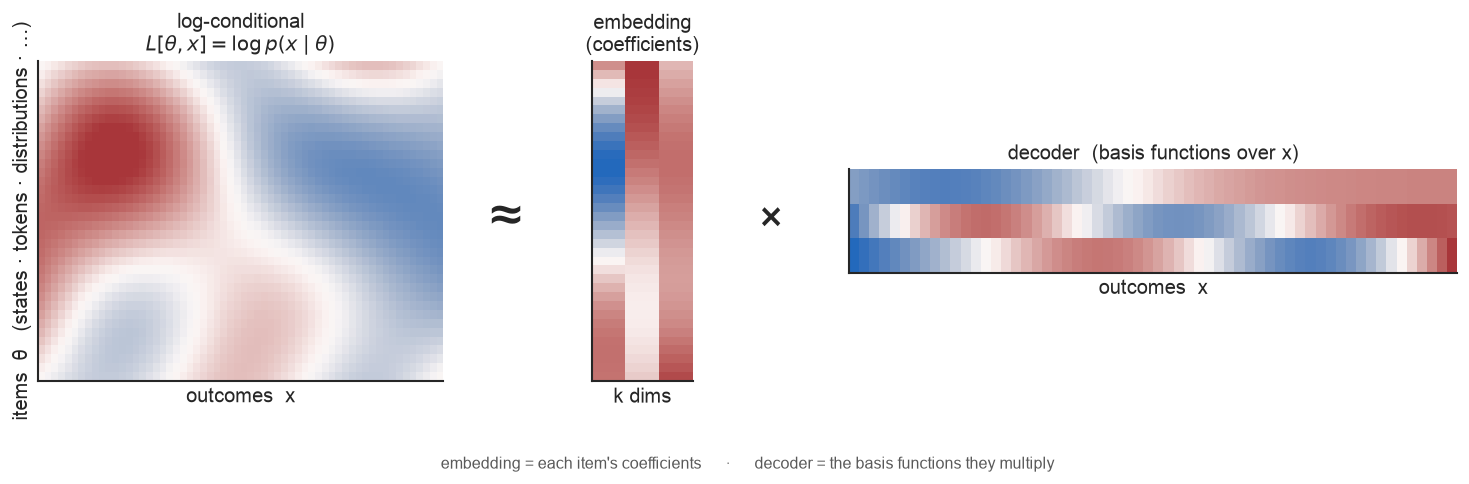

In [2]:
# a representative (low-rank, smooth) log-conditional and its embedding × decoder factorization
n_, m_ = 36, 60; ti = np.linspace(0, 1, n_); tj = np.linspace(0, 1, m_)
U = np.stack([np.sin(np.pi * ti), np.sin(2 * np.pi * ti), np.cos(np.pi * ti)], 1)
V = np.stack([np.cos(np.pi * tj), np.sin(2 * np.pi * tj), np.sin(3 * np.pi * tj)], 1)
Ldemo = (U * np.array([1.0, 0.6, 0.4])) @ V.T                 # log p(x|θ): a smooth rank-3 field
Uh, Sh, Vth = np.linalg.svd(Ldemo, full_matrices=False); kk = 3
Ehero, Dhero = Uh[:, :kk] * Sh[:kk], Vth[:kk]

fig = plt.figure(figsize=(13, 4.3)); fig.set_constrained_layout(False)
axP = fig.add_axes([0.045, 0.20, 0.26, 0.62]); axE = fig.add_axes([0.40, 0.20, 0.065, 0.62])
axD = fig.add_axes([0.565, 0.41, 0.39, 0.20])
v = np.percentile(np.abs(Ldemo), 98)
axP.imshow(Ldemo, aspect="auto", cmap="vlag", vmin=-v, vmax=v)
axE.imshow(Ehero, aspect="auto", cmap="vlag"); axD.imshow(Dhero, aspect="auto", cmap="vlag")
for a in (axP, axE, axD):
    a.set_xticks([]); a.set_yticks([])
axP.set_title("log-conditional\n$L[\\theta,x]=\\log p(x\\mid\\theta)$"); axE.set_title("embedding\n(coefficients)")
axD.set_title("decoder  (basis functions over x)")
axP.set_ylabel("items  θ   (states · tokens · distributions · …)"); axP.set_xlabel("outcomes  x")
axE.set_xlabel("k dims"); axD.set_xlabel("outcomes  x")
fig.text(0.345, 0.51, "≈", fontsize=34, ha="center", va="center")
fig.text(0.515, 0.51, "×", fontsize=26, ha="center", va="center")
fig.text(0.5, 0.03, "embedding = each item's coefficients      ·      "
                    "decoder = the basis functions they multiply",
         ha="center", fontsize=9.5, color="0.35")
plt.show()

## 1. Latent structure sets the geometry

One recipe throughout, in increasing structural complexity: a **latent structure** → **co-occurrence** (diffusion on it, $(I-\gamma P)^{-1}$) → factor $\log p(\text{outcome}\mid\text{context})$ → **embedding = the structure's harmonics**. We walk *up the complexity of the structure* and the optimal embedding follows — so representational geometry is **predictable from the structure of the data**: change the structure, change the geometry.

**Graphs.** The simplest structures are graphs; co-occurrence falls off with **diffusion distance** (all paths). The graph's shape sets the geometry, and the **boundary** sets the shape:
- **Periodic** (a loop) → Fourier modes → a **circle** (e.g. calendar months).
- **Open** (ends) → standing-wave cosines → a **horseshoe/arch** — faithful center, distorted edges (the geometry seen in LLMs).
- **2-D / curved / clustered** → an open grid (a distorted sheet), a sphere (degree-1 harmonics), community blocks.

(A symmetric walk keeps the matrix symmetric, so embedding and decoder coincide; the directed/asymmetric case is §4.)

In [3]:
# central operation + co-occurrence (diffusion on the latent graph) + the shared 3-panel template
def factor_logcond(Llog):                                  # log-conditional -> embedding × decoder (correspondence-analysis SVD, gauge-centered)
    N, M = Llog.shape; w = np.full(N, 1.0 / N)
    pp = np.exp(Llog - Llog.max(1, keepdims=True)); pp /= pp.sum(1, keepdims=True); nu = pp.mean(0); nu /= nu.sum()
    Lc = Llog - (Llog @ nu)[:, None]                       # gauge only: remove the per-context (row) offset softmax ignores; base rate kept
    U, Sv, Vt = np.linalg.svd(np.sqrt(w)[:, None] * Lc * np.sqrt(nu)[None, :], full_matrices=False)
    return Lc, (U / np.sqrt(w)[:, None]) * Sv, Vt / np.sqrt(nu)[None, :], Sv, nu

def logcond_from_sim(K):                                   # symmetric co-occurrence kernel -> log p(word | context)
    return np.log(K / K.sum(1, keepdims=True) + 1e-12)

def walk_cooccur(A, gamma=0.8):                            # diffusion co-occurrence on a graph: Σ γ^t P^t = (I − γP)⁻¹, decays with diffusion distance (all paths)
    deg = A.sum(1); P = A / deg[:, None]; pi = deg / deg.sum()
    M = np.linalg.inv(np.eye(len(A)) - gamma * P)
    J = pi[:, None] * M; return 0.5 * (J + J.T)

def cooccur_logcond(A, gamma=0.8):                        # -> log p(token | nearby context)
    return logcond_from_sim(walk_cooccur(A, gamma))

def _clean2d(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

def triptych(name, draw_latent, Lc, draw_embed, dL=2, dE=2, embed_title="embedding"):   # shared template: latent structure -> log-conditional -> embedding
    fig = plt.figure(figsize=(11.5, 3.5)); fig.set_constrained_layout(False)
    axA = fig.add_axes([0.02, 0.08, 0.27, 0.74], projection="3d" if dL == 3 else None)
    axB = fig.add_axes([0.40, 0.12, 0.20, 0.66])
    axC = fig.add_axes([0.70, 0.08, 0.27, 0.74], projection="3d" if dE == 3 else None)
    draw_latent(axA); axA.set_title(name, fontsize=12)
    lim = np.percentile(np.abs(Lc), 98); axB.imshow(Lc, cmap="vlag", vmin=-lim, vmax=lim)
    axB.set_xticks([]); axB.set_yticks([]); axB.set_title("log-conditional", fontsize=10)
    axB.set_xlabel("word", fontsize=9); axB.set_ylabel("word", fontsize=9)   # square: both axes are the same word set (co-occurrence)
    draw_embed(axC); axC.set_title(embed_title, fontsize=12)
    fig.text(0.335, 0.46, "→", fontsize=30, ha="center", va="center", color="0.4")
    fig.text(0.645, 0.46, "→", fontsize=30, ha="center", va="center", color="0.4")
    plt.show()

def _draw(ax, A, pos, color, cmap):                       # draw a graph at given node positions
    ii, jj = np.where(np.triu(A, 1) > 0); d = pos.shape[1]; seg = [[pos[a], pos[b]] for a, b in zip(ii, jj)]
    if d == 2:
        from matplotlib.collections import LineCollection
        ax.add_collection(LineCollection(seg, colors="0.85", linewidths=0.3, zorder=0))
        ax.scatter(pos[:, 0], pos[:, 1], c=color, cmap=cmap, s=24, zorder=2)
        ax.set_aspect("equal", adjustable="datalim"); ax.margins(0.08); _clean2d(ax)
    else:
        for s in seg: ax.plot(*zip(*s), color="0.85", lw=0.2)
        ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], c=color, cmap=cmap, s=14); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

def show_graph(name, A, pos, k, color, *, gamma=0.8, cmap="twilight", sort=None):
    Lc, E, D, Sv, nu = factor_logcond(cooccur_logcond(A, gamma)); emb = E[:, :k]; gd = pos.shape[1]
    o = np.argsort(sort) if sort is not None else np.arange(len(A))
    def de(ax):
        if k == 2:
            ax.scatter(emb[:, 0], emb[:, 1], c=color, cmap=cmap, s=24); ax.set_aspect("equal", adjustable="datalim"); ax.margins(0.08); _clean2d(ax)
        else:
            u = emb / np.linalg.norm(emb, axis=1, keepdims=True); ax.scatter(u[:, 0], u[:, 1], u[:, 2], c=color, cmap=cmap, s=14)
            ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    triptych(name, lambda ax: _draw(ax, A, pos, color, cmap), Lc[np.ix_(o, o)], de, dL=gd, dE=k)
    print(f"{name}: spectrum {np.round(Sv[:6], 2)}")

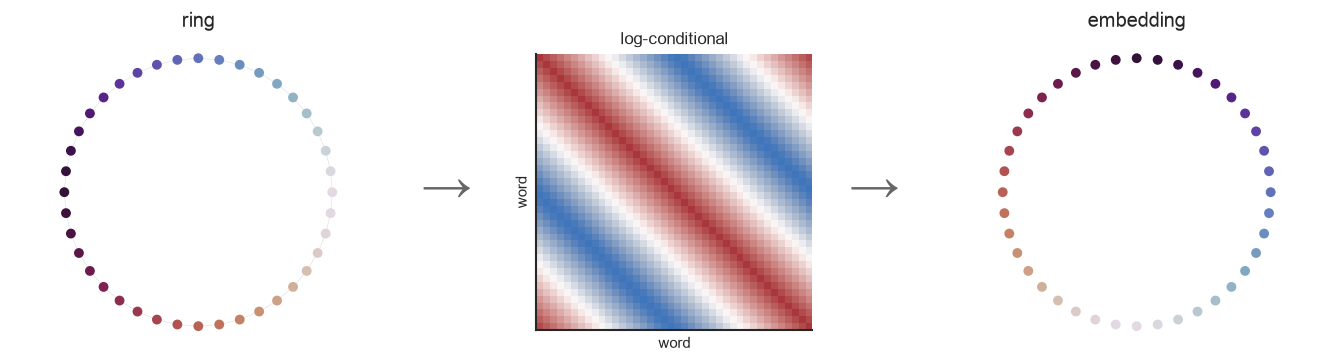

ring: spectrum [2.78 2.78 0.29 0.29 0.09 0.09]


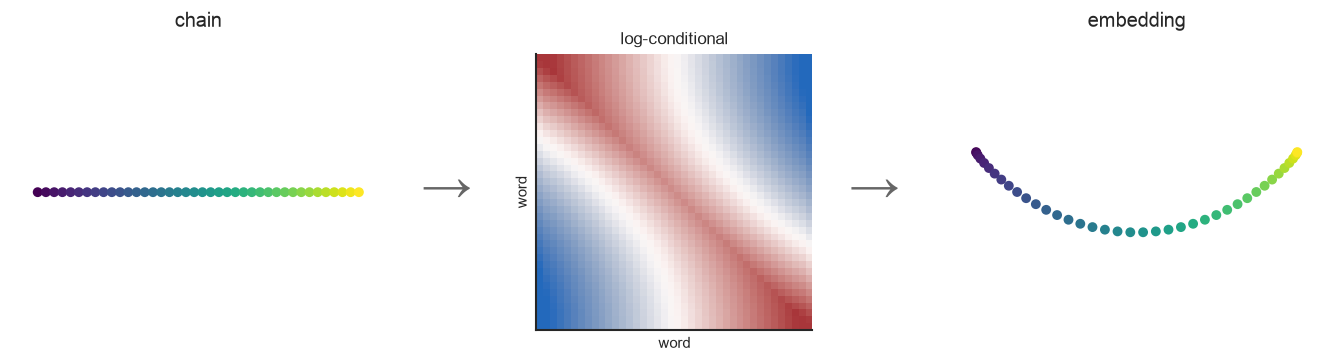

chain: spectrum [5.61 2.43 0.61 0.44 0.22 0.18]


In [4]:
# 1-D, open vs periodic boundary: horseshoe vs circle
n = 40
# periodic (ring) -> circle
A = np.zeros((n, n))
for i in range(n): A[i, (i + 1) % n] = A[i, (i - 1) % n] = 1
th = 2 * np.pi * np.arange(n) / n
show_graph("ring", A, np.c_[np.cos(th), np.sin(th)], 2, np.arange(n), cmap="twilight")
# open (chain) -> horseshoe / arch
A = np.zeros((n, n))
for i in range(n - 1): A[i, i + 1] = A[i + 1, i] = 1
show_graph("chain", A, np.c_[np.arange(n), np.zeros(n)], 2, np.arange(n), cmap="viridis")

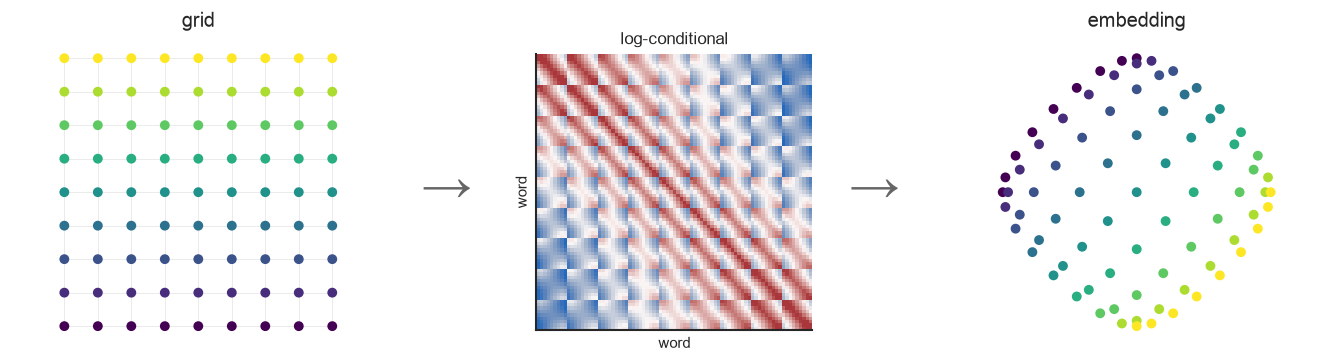

grid: spectrum [1.41 1.41 0.68 0.24 0.21 0.11]


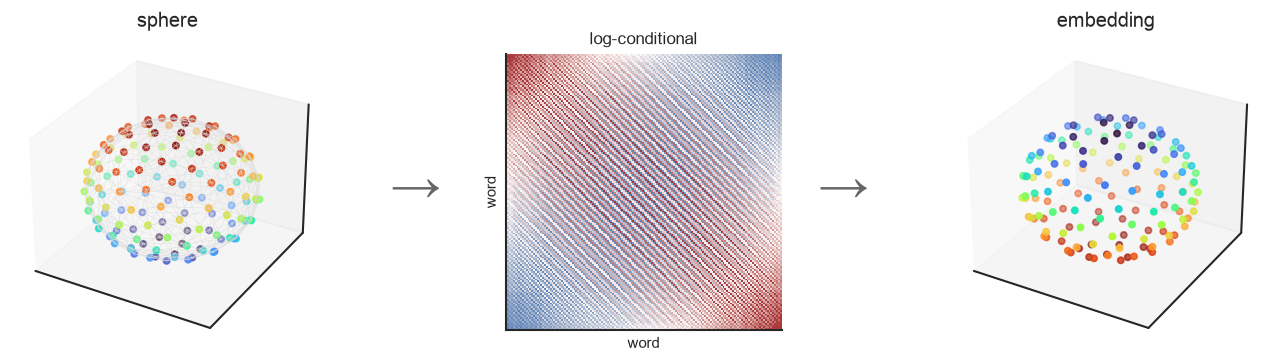

sphere: spectrum [0.97 0.96 0.92 0.11 0.11 0.1 ]


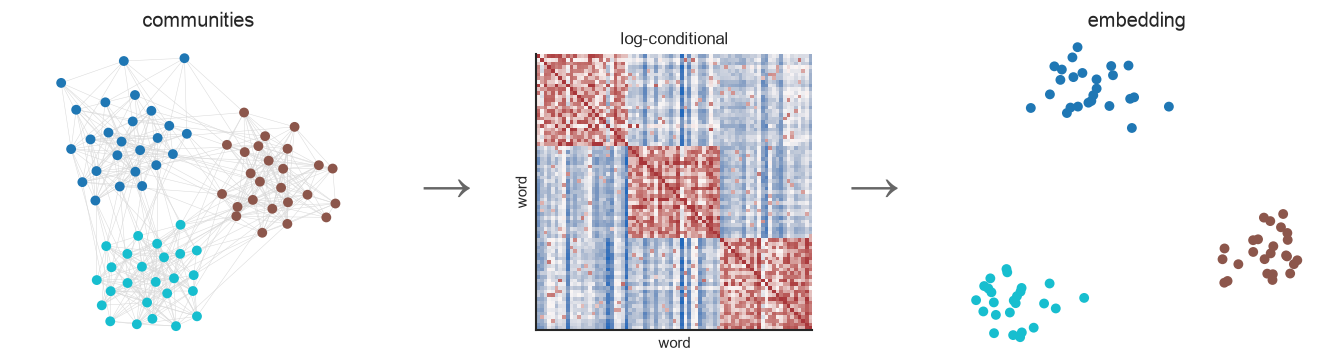

communities: spectrum [0.47 0.41 0.24 0.13 0.11 0.1 ]


In [5]:
# 2-D and clusters: open grid -> distorted sheet (horseshoe cross-sections, matching LLM in-context grids); sphere; communities
m = 9; N = m * m; A = np.zeros((N, N)); ij = np.array([(i, j) for i in range(m) for j in range(m)])
idx = {tuple(c): k for k, c in enumerate(ij)}
for i in range(m):
    for j in range(m):
        if i + 1 < m: a, b = idx[(i, j)], idx[(i + 1, j)]; A[a, b] = A[b, a] = 1
        if j + 1 < m: a, b = idx[(i, j)], idx[(i, j + 1)]; A[a, b] = A[b, a] = 1
show_graph("grid", A, ij[:, ::-1].astype(float), 2, ij[:, 0], cmap="viridis")

Ns = 150; ii = np.arange(Ns); gold = np.pi * (1 + 5 ** 0.5)
zc = 1 - 2 * (ii + 0.5) / Ns; rc = np.sqrt(1 - zc ** 2); ph = gold * ii
sph = np.stack([rc * np.cos(ph), rc * np.sin(ph), zc], 1)
D2 = ((sph[:, None] - sph[None]) ** 2).sum(-1); A = np.zeros((Ns, Ns))
for i in range(Ns):
    nb = np.argsort(D2[i])[1:9]; A[i, nb] = A[nb, i] = 1
show_graph("sphere", A, sph, 3, zc, cmap="turbo", sort=zc)

import networkx as nx
rg = np.random.default_rng(0); lab = np.repeat(np.arange(3), 25); Nc = len(lab); A = np.zeros((Nc, Nc))
for i in range(Nc):
    for j in range(i + 1, Nc):
        if rg.random() < (0.45 if lab[i] == lab[j] else 0.04): A[i, j] = A[j, i] = 1
pos = np.array(list(nx.spring_layout(nx.from_numpy_array(A), seed=1, k=0.3).values()))
show_graph("communities", A, pos, 2, lab, cmap="tab10", sort=lab)

**Two more order-1 cases — the baseline and a warped metric.**

- **Categorical (simplex).** With *no* relational structure — a complete graph, every word equally near every other — the embedding is a **regular simplex**: all items equidistant. This is the order-1 **lookup / confusability** baseline, and the structured cases are departures from it.
- **Log number line (Weber).** Same 1-D topology as the chain, but the *metric* is logarithmic, so large magnitudes **compress** — the mental number line / Weber–Fechner law. It's the structure's **distance**, not just its shape, that sets the geometry.

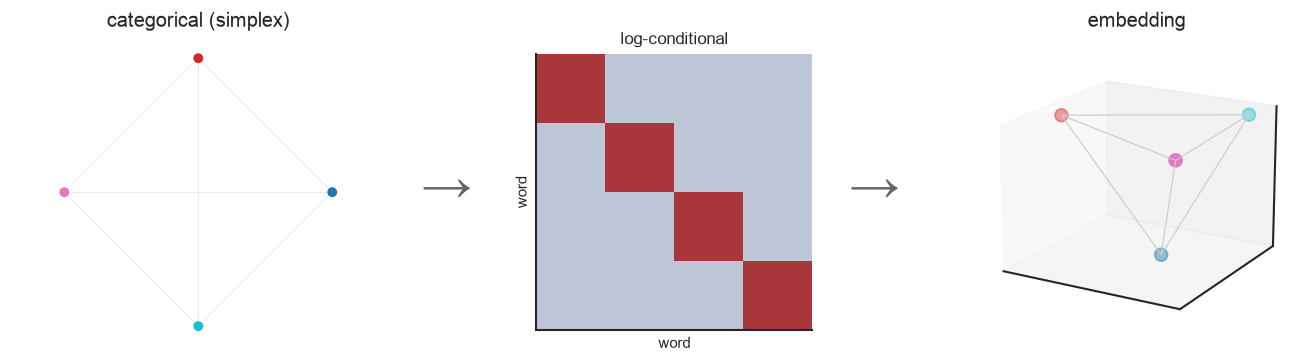

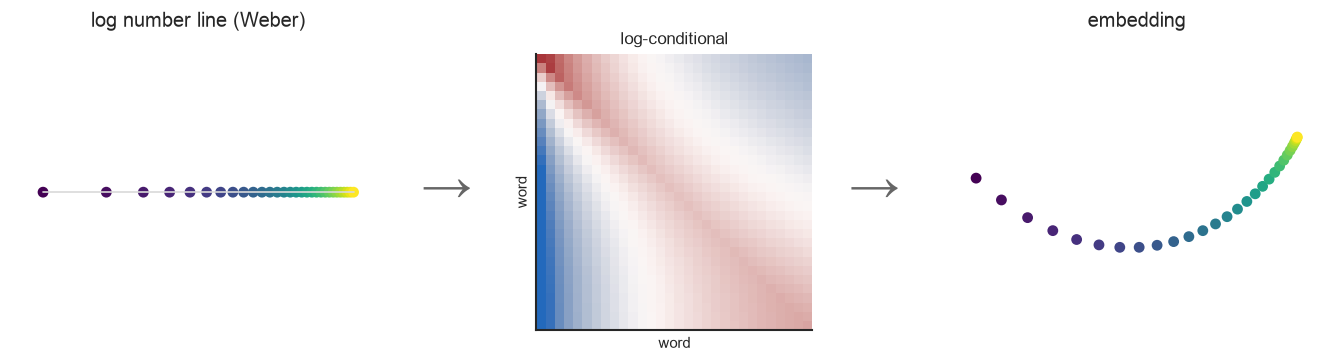

simplex = no structure (all equidistant);  log line = warped metric (large numbers compress)


In [6]:
# BASELINE (no structure) + a WARPED METRIC — two more order-1 cases
# (a) categorical: complete graph -> every word equidistant -> a simplex (the order-1 lookup/confusability baseline)
n = 4; A = 1 - np.eye(n); col = np.arange(n)
ang = 2 * np.pi * np.arange(n) / n; pos = np.c_[np.cos(ang), np.sin(ang)]
Lc, E, D, Sv, nu = factor_logcond(cooccur_logcond(A))
def de_simplex(ax):
    for a in range(n):
        for b in range(a + 1, n): ax.plot(*zip(E[a, :3], E[b, :3]), color="0.8", lw=0.7)
    ax.scatter(E[:, 0], E[:, 1], E[:, 2], c=col, cmap="tab10", s=60); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18, azim=-60)
triptych("categorical (simplex)", lambda ax: _draw(ax, A, pos, col, "tab10"), Lc, de_simplex, dL=2, dE=3)

# (b) log / Weber number line: a line whose METRIC is logarithmic -> large magnitudes compress
n = 30; x = np.log1p(np.arange(n)); Dist = np.abs(x[:, None] - x[None]); col = np.arange(n)
Lc, E, D, Sv, nu = factor_logcond(logcond_from_sim(np.exp(-2.0 * Dist)))   # 1-D: diffusion = exp(-lambda * distance)
def dl_log(ax):
    pp = np.c_[x, np.zeros(n)]; ax.plot(pp[:, 0], pp[:, 1], "-", color="0.85", lw=1); ax.scatter(pp[:, 0], pp[:, 1], c=col, cmap="viridis", s=30)
    ax.set_aspect("equal", adjustable="datalim"); ax.margins(0.1); _clean2d(ax)
def de_log(ax):
    ax.scatter(E[:, 0], E[:, 1], c=col, cmap="viridis", s=30); ax.set_aspect("equal", adjustable="datalim"); ax.margins(0.08); _clean2d(ax)
triptych("log number line (Weber)", dl_log, Lc, de_log, dL=2, dE=2)
print("simplex = no structure (all equidistant);  log line = warped metric (large numbers compress)")

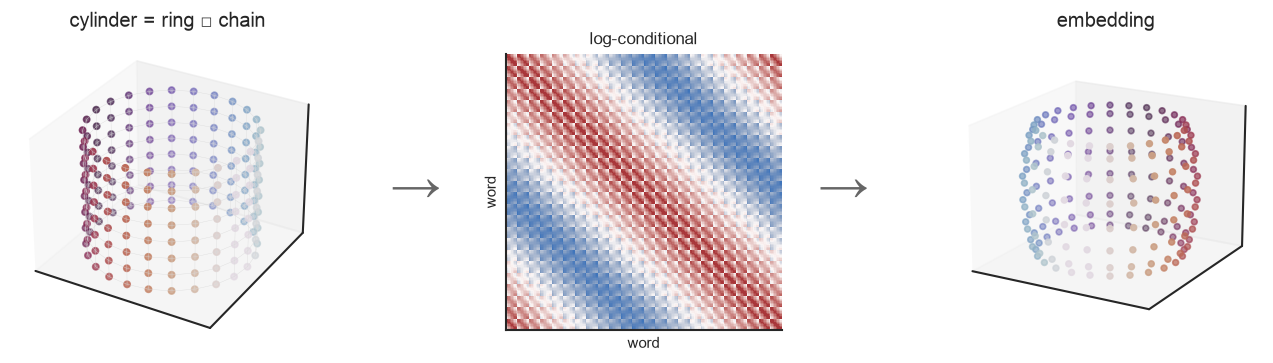

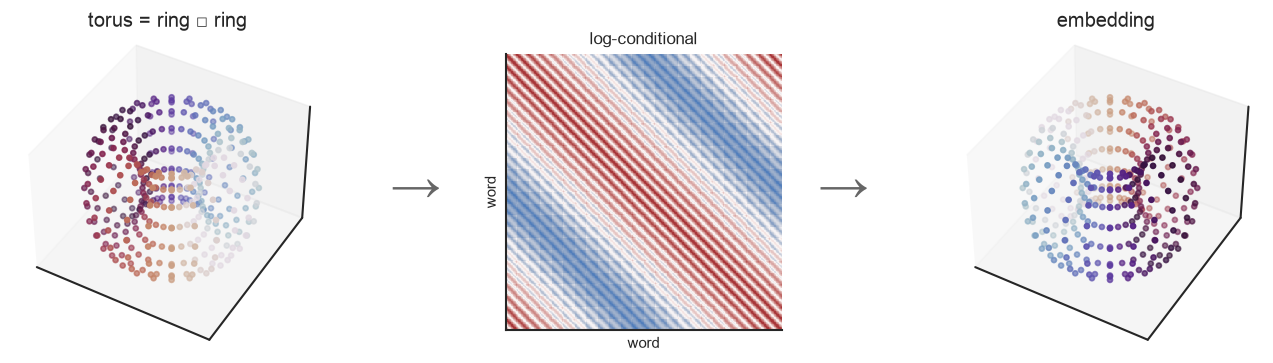

compositional: grid/cylinder/torus are products of 1-D factors -> the embedding is the product geometry


In [7]:
# COMPOSITIONAL latent structure = Cartesian product of factors (grid = path□path, cylinder = ring□chain, torus = ring□ring)
def cart_product(A1, A2):                                          # product graph: node (i,j); move along one factor at a time
    n1, n2 = len(A1), len(A2); A = np.zeros((n1 * n2, n1 * n2))
    for i in range(n1):
        for j in range(n2):
            for k in np.where(A1[i] > 0)[0]: A[i * n2 + j, k * n2 + j] = 1
            for k in np.where(A2[j] > 0)[0]: A[i * n2 + j, i * n2 + k] = 1
    return A
ringA = lambda n: np.array([[1.0 if abs(a - b) % n in (1, n - 1) else 0 for b in range(n)] for a in range(n)])
chainA = lambda n: np.array([[1.0 if abs(a - b) == 1 else 0 for b in range(n)] for a in range(n)])

# cylinder = ring □ chain  (one periodic factor, one open) -> embedding = circle × line
n1, n2 = 24, 8; A = cart_product(ringA(n1), chainA(n2))
th = np.array([2 * np.pi * i / n1 for i in range(n1) for j in range(n2)]); hh = np.array([j for i in range(n1) for j in range(n2)])
Lc, E, D, Sv, nu = factor_logcond(cooccur_logcond(A)); pos = np.c_[np.cos(th), np.sin(th), hh * 0.35]
def de_cyl(ax):
    ax.scatter(E[:, 0], E[:, 1], E[:, 2], c=th, cmap="twilight", s=12); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18, azim=-60)
triptych("cylinder = ring □ chain", lambda ax: _draw(ax, A, pos, th, "twilight"), Lc, de_cyl, dL=3, dE=3)

# torus = ring □ ring  (4-D flat torus -> shown as a donut via the two recovered ring-angles)
n1, n2 = 24, 16; A = cart_product(ringA(n1), ringA(n2))
t1 = np.array([2 * np.pi * i / n1 for i in range(n1) for j in range(n2)]); t2 = np.array([2 * np.pi * j / n2 for i in range(n1) for j in range(n2)])
Lc, E, D, Sv, nu = factor_logcond(cooccur_logcond(A))
donut = lambda u, v: np.c_[(2 + np.cos(v)) * np.cos(u), (2 + np.cos(v)) * np.sin(u), np.sin(v)]
def dl_tor(ax):
    P = donut(t1, t2); ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=t1, cmap="twilight", s=9); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=42, azim=-60)
def de_tor(ax):
    P = donut(np.arctan2(E[:, 1], E[:, 0]), np.arctan2(E[:, 3], E[:, 2])); ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=t1, cmap="twilight", s=9); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=42, azim=-60)
triptych("torus = ring □ ring", dl_tor, Lc, de_tor, dL=3, dE=3)
print("compositional: grid/cylinder/torus are products of 1-D factors -> the embedding is the product geometry")

**Composition — products of factors.** A latent structure can be a **Cartesian product** of simpler ones: grid = path □ path, **cylinder = ring □ chain**, **torus = ring □ ring**. The embedding is the **product geometry** — each factor keeps its own coordinates (a circle here, a line there) and you can translate along each factor independently. This is the same "product of independent factors" that, made all-binary, gives the analogies next.

### Factorial features & hierarchy

Climbing further from spatial graphs, two more structures:
- **Factorial** — independent binary attributes are the **all-binary product** (a hypercube): each attribute becomes a straight direction, so analogies (*king − man + woman = queen*) are literal vector arithmetic.
- **Hierarchical** — a **tree** (Saxe's branching diffusion: features spread through the internal nodes, read out at the leaves): ultrametric co-occurrence, nested clusters, modes = the tree's cuts coarse-to-fine.

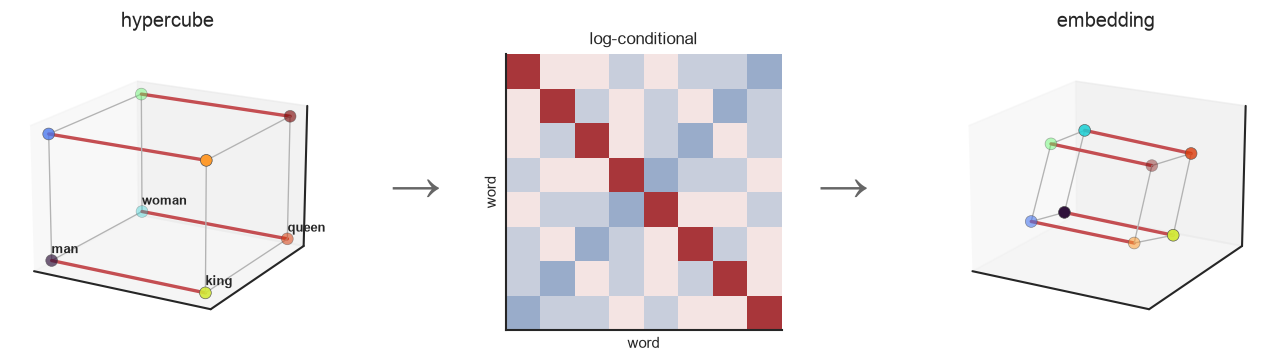

spectrum [0.23 0.23 0.23 0.08 0.08];  king−man+woman → word 6 = queen (True)


In [8]:
# LATENT STRUCTURE = independent binary attributes -> diffusion on the hypercube -> analogies (parallel edges)
import itertools
m = 3; B = np.array(list(itertools.product([-1, 1], repeat=m)))   # 2^m words at hypercube vertices (independent attributes)
H = (B[:, None] != B[None]).sum(-1)                               # Hamming distance (# differing attributes)
A = (H == 1).astype(float)                                        # hypercube graph: neighbors differ in one attribute
Lc, E, D, Sv, nu = factor_logcond(cooccur_logcond(A))            # diffusion distance on the cube = Hamming (no multiplicity)
cols = plt.get_cmap("turbo")(np.linspace(0, 1, len(B)))          # one color per word, shared by both cubes
idx = {tuple(b): i for i, b in enumerate(B)}
named = [(idx[(-1, -1, -1)], "man"), (idx[(-1, 1, -1)], "woman"), (idx[(1, -1, -1)], "king"), (idx[(1, 1, -1)], "queen")]

def cube_draw(P, label=False):                                    # same drawing for latent (B) and embedding (top-3 coords)
    def f(ax):
        for i in range(len(B)):
            for j in range(i + 1, len(B)):
                if H[i, j] == 1:                                 # hypercube edge = flip one attribute (red = the royal flip)
                    royal = B[i][0] != B[j][0]
                    ax.plot(*zip(P[i], P[j]), color="C3" if royal else "0.7", lw=2.0 if royal else 0.8, zorder=1)
        ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=cols, s=50, edgecolor="0.3", lw=0.4, zorder=3)
        if label:
            for i, nm in named: ax.text(P[i, 0], P[i, 1], P[i, 2] + 0.12, nm, fontsize=8, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18, azim=-60)
    return f

triptych("hypercube", cube_draw(B.astype(float), label=True), Lc, cube_draw(E[:, :3]), dL=3, dE=3)
pred = E[idx[(1, -1, -1)]] - E[idx[(-1, -1, -1)]] + E[idx[(-1, 1, -1)]]; nn = int(np.argmin(((E - pred) ** 2).sum(1)))
print(f"spectrum {Sv[:5].round(2)};  king−man+woman → word {nn} = queen ({nn == idx[(1, 1, -1)]})")

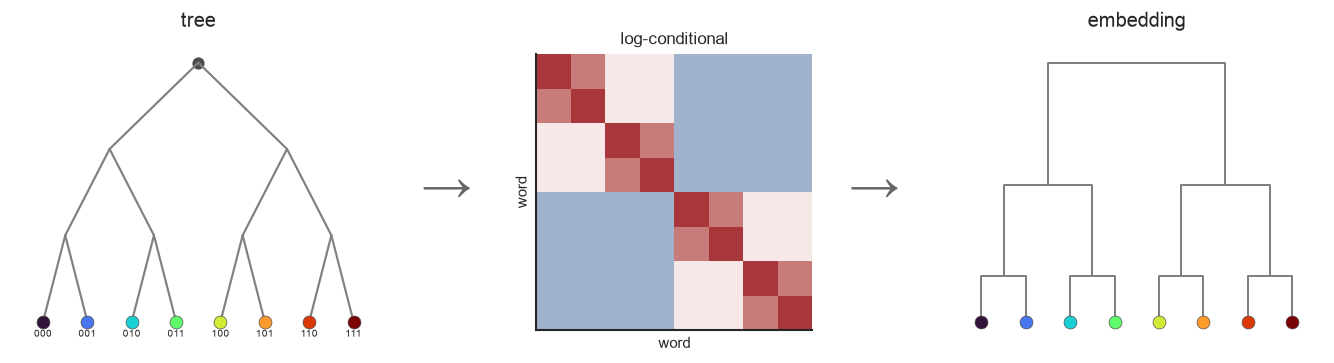

spectrum by level: [1.277 0.5   0.5   0.123 0.123 0.123 0.123 0.   ]


In [9]:
# LATENT STRUCTURE = a tree -> diffusion through the tree (Saxe branching diffusion) -> nested embedding
import itertools
from scipy.cluster.hierarchy import linkage
depth, branch = 3, 2; N = branch ** depth
addr = [tuple(a) for a in itertools.product(range(branch), repeat=depth)]   # leaves = the words (paths from the root)
nodes = [t for L in range(depth + 1) for t in itertools.product(range(branch), repeat=L)]   # all tree nodes (incl. internal)
ixn = {nd: i for i, nd in enumerate(nodes)}
A = np.zeros((len(nodes), len(nodes)))
for nd in nodes:
    if nd: A[ixn[nd], ixn[nd[:-1]]] = A[ixn[nd[:-1]], ixn[nd]] = 1          # parent-child edges
leaf_id = [ixn[a] for a in addr]                                            # words diffuse through the internal nodes; read out the leaves
Jl = walk_cooccur(A, 0.85)[np.ix_(leaf_id, leaf_id)]                        # leaf-leaf diffusion co-occurrence -> ultrametric (no multiplicity: trees are acyclic)
Lc, E, D, Sv, nu = factor_logcond(logcond_from_sim(Jl))
labels = ["".join(map(str, a)) for a in addr]; cols = plt.get_cmap("turbo")(np.linspace(0, 1, N))   # one color per leaf, shared by both panels
leaf_x = {a: i for i, a in enumerate(addr)}
node_x = lambda nd: leaf_x[nd] if len(nd) == depth else np.mean([leaf_x[a] for a in addr if a[:len(nd)] == nd])

def leaves(ax, label=False):                                                # same leaf order & colors in both panels
    for i in range(N):
        ax.scatter(i, 0, c=[cols[i]], s=60, zorder=3, edgecolor="0.3", lw=0.4)
        if label: ax.annotate(labels[i], (i, 0), fontsize=6, xytext=(0, -9), textcoords="offset points", ha="center")
    _clean2d(ax)

def draw_tree(ax):                                                          # latent structure: the generating tree
    for nd in nodes:
        if nd: ax.plot([node_x(nd[:-1]), node_x(nd)], [depth - len(nd) + 1, depth - len(nd)], "-", color="0.5", lw=1.3)
    ax.scatter([node_x(())], [depth], c="0.3", s=40); leaves(ax, label=True); ax.margins(0.1)

def draw_dendro(ax):                                                        # embedding: dendrogram of the full embedding distances
    Z = linkage(E, method="average"); x = {i: i for i in range(N)}; y = {i: 0.0 for i in range(N)}
    for k, (a, b, h, _) in enumerate(Z):
        a, b = int(a), int(b); nd = N + k
        ax.plot([x[a], x[a], x[b], x[b]], [y[a], h, h, y[b]], color="0.5", lw=1.2); x[nd] = 0.5 * (x[a] + x[b]); y[nd] = h
    leaves(ax); ax.margins(0.1)

triptych("tree", draw_tree, Lc, draw_dendro, dL=2, dE=2)
print(f"spectrum by level: {Sv[:N].round(3)}")

### Hierarchy as orthogonal subspaces (Park et al. 2024)

Same `diffuse -> factor` as the tree, but the embedding has a sharper structure: **categorical concepts form simplices, and hierarchically related concepts live in orthogonal subspaces** (Park, Choe & Veitch 2024). With 3 super-categories each split into 3 subs, the embedding is a **simplex of simplices** — the supers form a big triangle, and each super's subs form their own small triangle at its vertex. And each child simplex sits in a subspace **orthogonal to its parent direction** (second view; `max |cos(parent, child)| ~ 0`). It falls straight out of the factorization: the SVD modes are the tree's level-by-level cuts, orthogonal by construction.

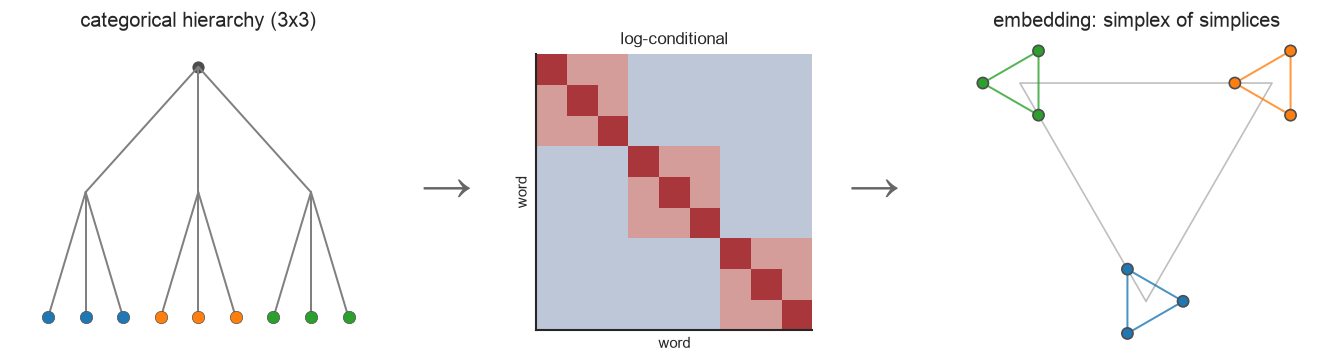

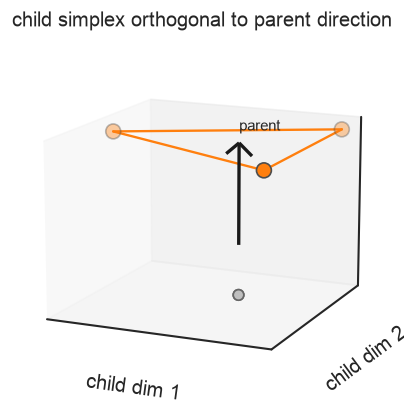

cross-level orthogonality: max |cos(parent, child)| = 0.000


In [10]:
# HIERARCHY AS ORTHOGONAL SUBSPACES (Park et al. 2024): categories -> simplices, parent dir orthogonal to child subspace
import itertools
b = 3                                                              # 3 super-categories, each with 3 sub-categories
nodes = [()] + [(s,) for s in range(b)] + [(s, k) for s in range(b) for k in range(b)]
ixn = {nd: i for i, nd in enumerate(nodes)}; A = np.zeros((len(nodes),) * 2)
for nd in nodes:
    if nd: A[ixn[nd], ixn[nd[:-1]]] = A[ixn[nd[:-1]], ixn[nd]] = 1
leaves = [nd for nd in nodes if len(nd) == 2]; lid = [ixn[nd] for nd in leaves]
Lc, E, D, Sv, nu = factor_logcond(logcond_from_sim(walk_cooccur(A)[np.ix_(lid, lid)]))
sup = np.array([nd[0] for nd in leaves]); cols = plt.get_cmap("tab10")(sup / 10); gm = E.mean(0)
cen = np.array([E[sup == s, :2].mean(0) for s in range(b)])

leaf_x = {nd: i for i, nd in enumerate(leaves)}
nx_ = lambda nd: leaf_x[nd] if len(nd) == 2 else (np.mean([leaf_x[l] for l in leaves if l[0] == nd[0]]) if len(nd) == 1 else (len(leaves) - 1) / 2)
def draw_tree(ax):                                                # latent: the categorical hierarchy
    for nd in nodes:
        if nd: ax.plot([nx_(nd[:-1]), nx_(nd)], [2 - len(nd[:-1]), 2 - len(nd)], "-", color="0.5", lw=1.2)
    for i in range(len(leaves)): ax.scatter(i, 0, c=[cols[i]], s=55, zorder=3, edgecolor="0.3", lw=0.4)
    ax.scatter([nx_(())], [2], c="0.3", s=40); ax.margins(0.12); _clean2d(ax)
def draw_sos(ax):                                                 # embedding: simplex of simplices (supers = big triangle, subs = small triangle)
    ax.plot(*np.vstack([cen, cen[:1]]).T, "-", color="0.75", lw=1, zorder=0)
    P = np.zeros((len(leaves), 2))
    for s in range(b):
        idx = np.where(sup == s)[0]; W = E[idx] - E[idx].mean(0); Q, _ = np.linalg.qr(W.T)
        P[idx] = cen[s] + (W @ Q[:, :2]) / (np.abs(W @ Q[:, :2]).max() + 1e-9) * 0.3
    for s in range(b):
        idx = np.where(sup == s)[0]; ax.plot(*np.vstack([P[idx], P[idx][:1]]).T, "-", color=cols[idx[0]], lw=1.2, alpha=0.8)
    ax.scatter(P[:, 0], P[:, 1], c=cols, s=45, edgecolor="0.3", zorder=3); ax.set_aspect("equal"); _clean2d(ax)
triptych("categorical hierarchy (3x3)", draw_tree, Lc, draw_sos, dL=2, dE=2, embed_title="embedding: simplex of simplices")

# second view (Park cross-product): a child simplex sits orthogonal to its parent direction
s0 = 1; zc = E[sup == s0].mean(0) - gm; zc /= np.linalg.norm(zc)
W = E[sup == s0] - E[sup == s0].mean(0); Q, _ = np.linalg.qr(W.T); X, Y, Z = E @ Q[:, 0], E @ Q[:, 1], E @ zc
fig = plt.figure(figsize=(4.4, 4.0)); ax = fig.add_subplot(111, projection="3d")
oth = sup != s0; ax.scatter(X[oth], Y[oth], Z[oth], c="0.75", s=40, edgecolor="0.4")
i0 = np.where(sup == s0)[0]; ax.scatter(X[i0], Y[i0], Z[i0], c=cols[i0], s=80, edgecolor="0.3", zorder=5)
for a_ in range(3):
    for c_ in range(a_ + 1, 3): ax.plot([X[i0[a_]], X[i0[c_]]], [Y[i0[a_]], Y[i0[c_]]], [Z[i0[a_]], Z[i0[c_]]], color=cols[i0[0]], lw=1.4)
ax.quiver(0, 0, 0, 0, 0, Z[i0].mean(), color="k", lw=2, arrow_length_ratio=0.12); ax.text(0, 0, Z[i0].mean() * 1.12, "parent", fontsize=9)
ax.set_xlabel("child dim 1"); ax.set_ylabel("child dim 2"); ax.set_zlabel("parent dir")
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=14, azim=-66); ax.set_title("child simplex orthogonal to parent direction")
plt.show()
between = [E[sup == s].mean(0) - gm for s in range(b)]; within = [E[i] - E[sup == sup[i]].mean(0) for i in range(len(leaves))]
u = lambda v: v / (np.linalg.norm(v) + 1e-12)
print(f"cross-level orthogonality: max |cos(parent, child)| = {max(abs(u(bd) @ u(wd)) for bd in between for wd in within if np.linalg.norm(wd) > 1e-9):.3f}")

**Takeaway.** Across all of §1 — the no-structure baseline (simplex), 1-D rings/chains (and the log/Weber number line), product manifolds (grid / cylinder / torus), the sphere, communities, the factorial hypercube, the hierarchical tree — it is **one operation**: diffuse on the latent structure, factor the log-conditional, read the embedding off as that structure's harmonics. The geometry is set entirely by the structure — the thesis this project builds on. (When *several* structures share one node set, the codes interfere — that's superposition, §2.)

## 2. Stack, share, superpose

Put several structures into one representation and what happens depends on two questions: do they live on the **same words** or **different words**, and — if the same — are their structures **aligned** (same modes) or not? The optimal embedding is still a factorization of the combined log-conditional; it either gives each structure its own dimensions (**stack**), reuses dimensions (**share**), or — when there aren't enough — packs them with interference (**superpose**). The axis underneath all of it is **capacity**.

- **Disjoint words** (block-diagonal co-occurrence) → **stack as a union**: each structure in its own orthogonal subspace — *two separate circles*, rank adds.
- **Same words, independent structures** → **stack as a product**: every word carries both coordinates — *a torus*, rank adds.
- **Same words, aligned relations** → **share**: the relations reuse one set of modes — *one circle*, rank saturates.
- **Over capacity** (more co-occurring features than dimensions) → **superpose**: non-orthogonal packing, rank no longer adds — needs sparsity + a nonlinear readout (the special case, §2 finale).

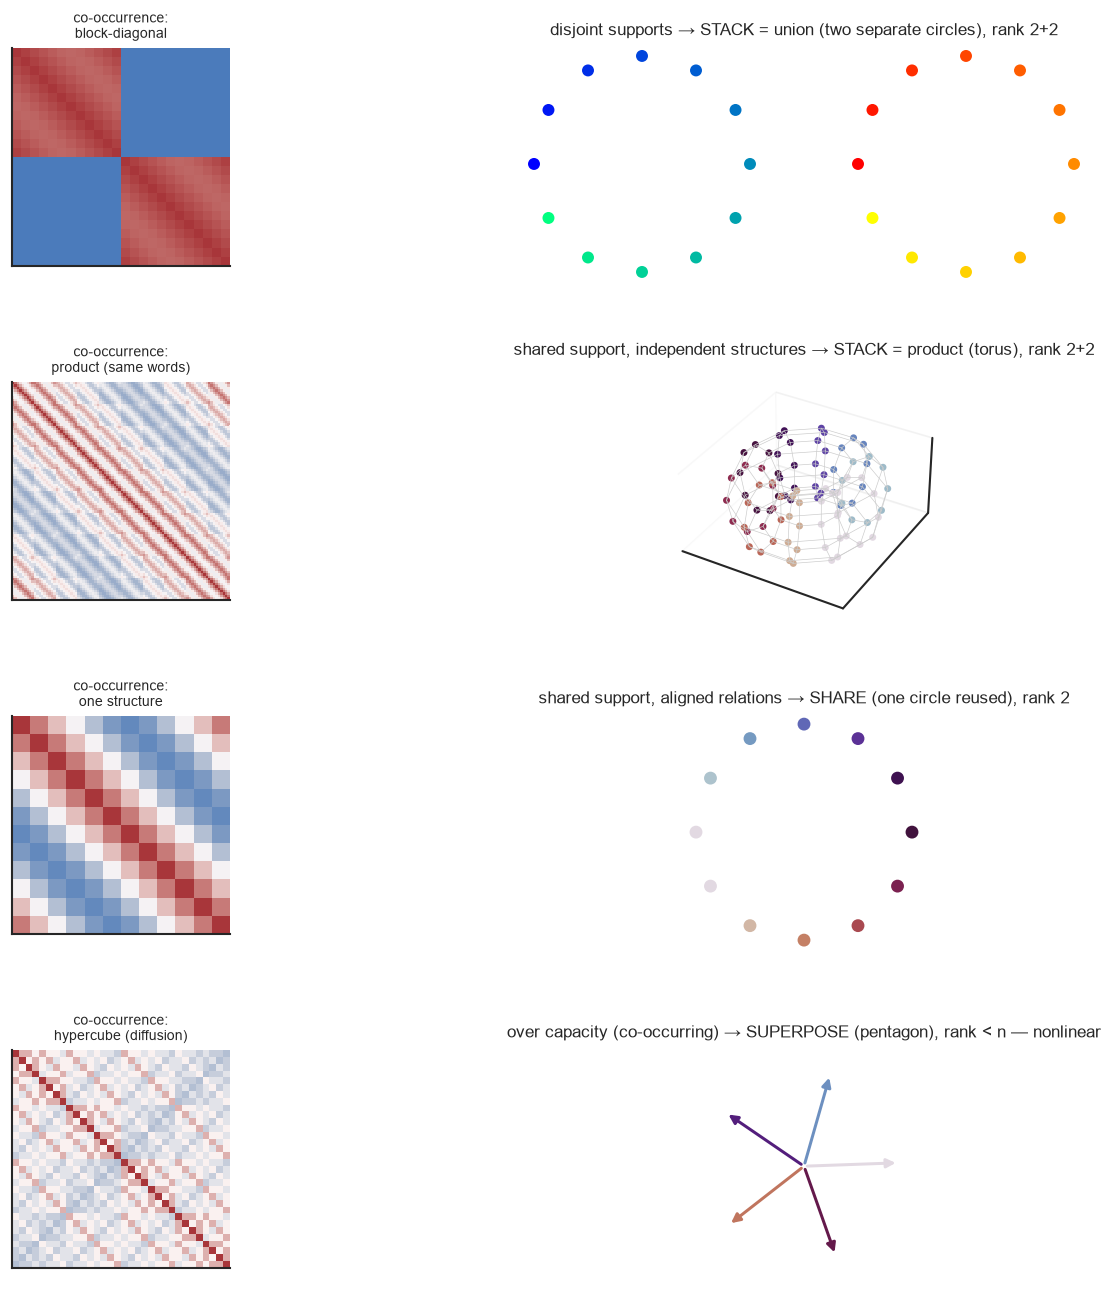

stack(union) | stack(product) | share | superpose


In [11]:
# STACK / SHARE / SUPERPOSE — four cases (rows): co-occurrence (left) -> embedding (right)
def ring(n):
    A = np.zeros((n, n))
    for i in range(n): A[i, (i + 1) % n] = 1; A[i, (i - 1) % n] = 1
    return A
def cart(A, B):                                                              # Cartesian product graph (shared support, independent factors)
    nA, nB = len(A), len(B); N = nA * nB; G = np.zeros((N, N)); ix = lambda i, j: i * nB + j
    for i in range(nA):
        for j in range(nB):
            for k in range(nA):
                if A[i, k]: G[ix(i, j), ix(k, j)] = 1
            for l in range(nB):
                if B[j, l]: G[ix(i, j), ix(i, l)] = 1
    return G
def unitcirc(A):                                                            # embed a ring -> project to the unit circle (clean)
    _, E, _, _, _ = factor_logcond(cooccur_logcond(A)); e = E[:, :2]; return e / np.linalg.norm(e, axis=1, keepdims=True)
def train_super(n, d=2, S=0.05, steps=3000, bs=1024, lr=1e-2, seed=0):       # nonlinear sparse autoencoder (superposition)
    g = torch.Generator().manual_seed(seed); W = torch.nn.Parameter(0.1 * torch.randn(d, n, generator=g)); b = torch.nn.Parameter(torch.zeros(n)); opt = torch.optim.Adam([W, b], lr=lr)
    for _ in range(steps):
        x = (torch.rand(bs, n, generator=g) < S).float() * torch.rand(bs, n, generator=g); xr = torch.relu((x @ W.T) @ W + b); loss = ((x - xr) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
    return W.detach().numpy()

fig = plt.figure(figsize=(11, 12)); top = 0.95; dh = 0.232
def cooc(r, L, t):
    ax = fig.add_axes([0.05, top - dh * r - 0.155, 0.165, 0.155]); m = np.abs(L).max() + 1e-9; ax.imshow(L, cmap="vlag", vmin=-m, vmax=m); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t, fontsize=8.5)
def clean(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

# (1) disjoint supports -> STACK = union (two circles)
n = 12; Big = np.zeros((2 * n, 2 * n)); Big[:n, :n] = ring(n); Big[n:, n:] = ring(n)
cooc(0, factor_logcond(cooccur_logcond(Big))[0], "co-occurrence:\nblock-diagonal")
cA = unitcirc(ring(n)); cB = unitcirc(ring(n)); ax = fig.add_axes([0.40, top - 0.165, 0.5, 0.165])
ax.scatter(cA[:, 0] - 1.5, cA[:, 1], c=np.arange(n), cmap="winter", s=38); ax.scatter(cB[:, 0] + 1.5, cB[:, 1], c=np.arange(n), cmap="autumn", s=38)
ax.set_aspect("equal"); clean(ax); ax.set_title("disjoint supports → STACK = union (two separate circles), rank 2+2", fontsize=10)

# (2) shared support, independent -> STACK = product (torus)
a, bn = 10, 9; G = cart(ring(a), ring(bn)); cooc(1, factor_logcond(cooccur_logcond(G))[0], "co-occurrence:\nproduct (same words)")
els = [(i, j) for i in range(a) for j in range(bn)]; t1 = np.array([2 * np.pi * i / a for i, j in els]); t2 = np.array([2 * np.pi * j / bn for i, j in els])
don = lambda u, v: np.c_[(2.4 + np.cos(v)) * np.cos(u), (2.4 + np.cos(v)) * np.sin(u), np.sin(v)]; ax = fig.add_axes([0.40, top - dh - 0.175, 0.5, 0.185], projection="3d")
for j in range(bn):
    u = np.r_[np.arange(a), 0] * 2 * np.pi / a; P = don(u, np.full(a + 1, 2 * np.pi * j / bn)); ax.plot(P[:, 0], P[:, 1], P[:, 2], color="0.8", lw=0.4)
for i in range(a):
    v = np.r_[np.arange(bn), 0] * 2 * np.pi / bn; P = don(np.full(bn + 1, 2 * np.pi * i / a), v); ax.plot(P[:, 0], P[:, 1], P[:, 2], color="0.8", lw=0.4)
P = don(t1, t2); ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=t1, cmap="twilight", s=10, depthshade=False)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=34, azim=-60); ax.set_box_aspect((1, 1, 0.5))
for pn in (ax.xaxis, ax.yaxis, ax.zaxis): pn.pane.set_facecolor((1, 1, 1, 0))
ax.set_title("shared support, independent structures → STACK = product (torus), rank 2+2", fontsize=10)

# (3) shared support, aligned -> SHARE (one circle)
A3 = ring(12) + 0.6 * ring(12); cooc(2, factor_logcond(cooccur_logcond(A3))[0], "co-occurrence:\none structure")
c3 = unitcirc(A3); ax = fig.add_axes([0.40, top - 2 * dh - 0.165, 0.5, 0.165]); ax.scatter(c3[:, 0], c3[:, 1], c=np.arange(12), cmap="twilight", s=45); ax.set_aspect("equal"); clean(ax)
ax.set_title("shared support, aligned relations → SHARE (one circle reused), rank 2", fontsize=10)

# (4) over capacity -> SUPERPOSE (pentagon).  co-occurrence = the hypercube's diffusion log-conditional
k = 5; V = 2 ** k; bits = np.array([[(v >> b) & 1 for b in range(k)] for v in range(V)])
Ahc = np.zeros((V, V))
for u in range(V):
    for w in range(V):
        if bin(u ^ w).count("1") == 1: Ahc[u, w] = 1
cooc(3, factor_logcond(cooccur_logcond(Ahc))[0], "co-occurrence:\nhypercube (diffusion)")
W = train_super(k, 2, 0.05); ax = fig.add_axes([0.40, top - 3 * dh - 0.165, 0.5, 0.165])
for i in range(k): ax.annotate("", xy=(W[0, i], W[1, i]), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=plt.cm.twilight(i / k), lw=1.8))
L = np.abs(W).max() * 1.25; ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_aspect("equal"); clean(ax)
ax.set_title("over capacity (co-occurring) → SUPERPOSE (pentagon), rank < n — nonlinear", fontsize=10)
plt.show()
print("stack(union) | stack(product) | share | superpose")

## 3. Uncertainty over a graph

A **belief over nodes** is represented by `belief · E` — the belief-weighted average of the node embeddings — so mixing beliefs is *literally averaging their codes*. Two kinds of belief change read straight off the circle:

- **Confidence = distance from the center.** Broadening a belief (sharp → flat) drives its code from the **rim** (certain) toward the **center** (no idea).
- **Mixing = the chord.** Interpolating between two beliefs A↔B moves the code along the **straight line** between them, through the uncertain interior; the midpoint belief is **two-peaked**.

(The ring's `L` is symmetric, so this factorization is just its eigendecomposition — `E` and `D` are the same Fourier harmonics, with `E` carrying the singular values.)

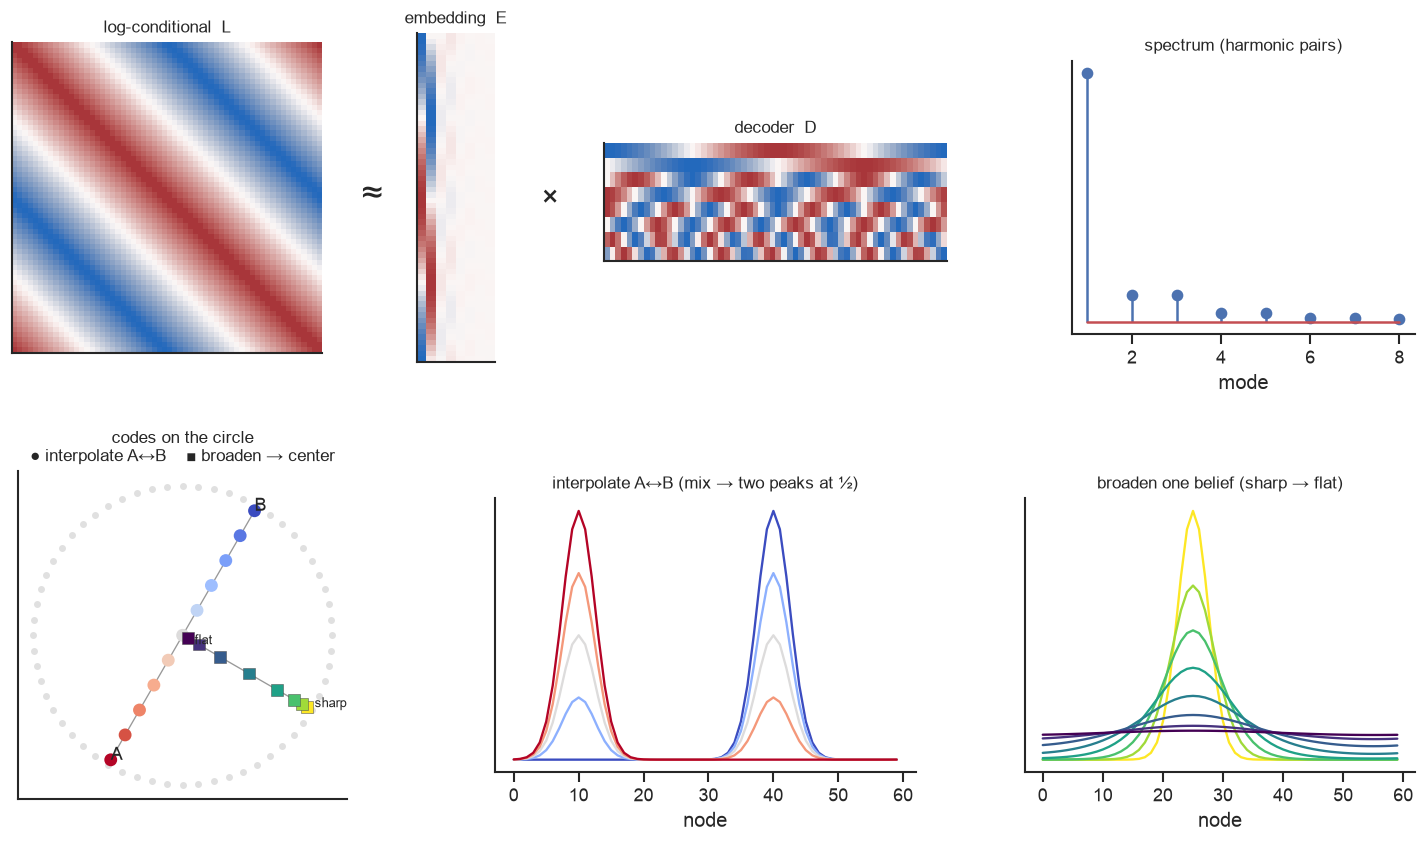

confidence = distance from center (sharp=rim, flat=center);  mixing = chord (interpolate A<->B through the interior)


In [12]:
# UNCERTAINTY over the ring: belief -> code = belief·E.  confidence = radius; mixing = chord.
n = 60; A = np.zeros((n, n))
for i in range(n): A[i, (i + 1) % n] = A[i, (i - 1) % n] = 1
Lc, E, D, Sv, nu = factor_logcond(cooccur_logcond(A)); th = 2 * np.pi * np.arange(n) / n
circ = E[:, :2] / np.linalg.norm(E[:, :2], axis=1).mean()
vm = lambda mu, k: (lambda b: b / b.sum())(np.exp(k * np.cos(th - mu)))
bA, bB = vm(th[10], 14), vm(th[40], 14)                                        # two beliefs to interpolate
ts = np.linspace(0, 1, 11); interp = np.array([(t * bA + (1 - t) * bB) @ circ for t in ts])
ks = np.array([14, 7, 4, 2.2, 1.2, 0.6, 0.25, 0.08]); broaden = np.array([vm(th[25], k) @ circ for k in ks])   # sharp -> flat
cb = plt.cm.viridis_r(np.linspace(0, 1, len(ks)))                              # one color list (sharp->flat), used in BOTH panels

fig = plt.figure(figsize=(13, 7.6))
def hm(box, M, t, sq=False):
    ax = fig.add_axes(box); v = np.percentile(np.abs(M), 98) + 1e-9
    ax.imshow(M, cmap="vlag", vmin=-v, vmax=v, aspect=("equal" if sq else "auto")); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t, fontsize=10)
# row 1: the decomposition (symmetric L -> eigendecomposition) + spectrum
hm([0.05, 0.56, 0.22, 0.34], Lc, "log-conditional  L", sq=True); fig.text(0.285, 0.72, "≈", fontsize=22)
hm([0.32, 0.55, 0.05, 0.36], E[:, :8], "embedding  E"); fig.text(0.40, 0.72, "×", fontsize=18)
hm([0.44, 0.66, 0.22, 0.13], D[:8], "decoder  D")
axs = fig.add_axes([0.74, 0.58, 0.22, 0.30]); axs.stem(range(1, 9), Sv[1:9]); axs.set_title("spectrum (harmonic pairs)", fontsize=10); axs.set_xlabel("mode"); axs.set_yticks([])
# row 2 left: codes on the circle — two trajectories
ax = fig.add_axes([0.05, 0.07, 0.24, 0.36]); ax.scatter(circ[:, 0], circ[:, 1], c="0.88", s=10); ax.scatter([0], [0], c="0.6", marker="+", s=50)
ax.plot(interp[:, 0], interp[:, 1], "-", color="0.6", lw=0.8, zorder=1); ax.scatter(interp[:, 0], interp[:, 1], c=ts, cmap="coolwarm", s=45, zorder=3)
ax.plot(broaden[:, 0], broaden[:, 1], "-", color="0.6", lw=0.8, zorder=1); ax.scatter(broaden[:, 0], broaden[:, 1], color=cb, s=50, zorder=3, marker="s", edgecolor="0.3", lw=0.3)
ax.annotate("A", bA @ circ, fontsize=11); ax.annotate("B", bB @ circ, fontsize=11)
ax.annotate("sharp", broaden[0], fontsize=8, xytext=(broaden[0, 0] + .05, broaden[0, 1]), textcoords="data")
ax.annotate("flat", broaden[-1], fontsize=8, xytext=(.08, -.06), textcoords="data")
ax.set_title("codes on the circle\n● interpolate A↔B    ■ broaden → center", fontsize=10); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
# row 2 mid: interpolation distributions (midpoint is two-peaked)
ax = fig.add_axes([0.37, 0.10, 0.27, 0.30])
for t in [0, 0.25, 0.5, 0.75, 1.0]: ax.plot(np.arange(n), t * bA + (1 - t) * bB, lw=1.4, color=plt.cm.coolwarm(t))
ax.set_title("interpolate A↔B (mix → two peaks at ½)", fontsize=10); ax.set_xlabel("node"); ax.set_yticks([])
# row 2 right: broadening distributions (sharp -> flat), SAME colors as the circle squares
ax = fig.add_axes([0.71, 0.10, 0.25, 0.30])
for i, k in enumerate(ks): ax.plot(np.arange(n), vm(th[25], k), lw=1.4, color=cb[i])
ax.set_title("broaden one belief (sharp → flat)", fontsize=10); ax.set_xlabel("node"); ax.set_yticks([])
plt.show()
print("confidence = distance from center (sharp=rim, flat=center);  mixing = chord (interpolate A<->B through the interior)")

## 4. Order 2 — the latent structure is an operation

At order 1 the latent structure was a *space*; at order 2 it is an *operation* — items **compose**, $c=a\star b$, so the conditional is a tensor $\log p(c\mid a,b)$ read out **bilinearly**, $\text{logit}_c(a,b)=e(a)^\top M_c\,e(b)$, one shared code in both slots. A shared code can combine two inputs only if composing them acts simply on their codes — for the operations here, each coordinate is a **frequency** the operation rotates, so the harmonics are the operation's Fourier modes and composing inputs adds their phases. The hero shows the bilinear readout; the gallery then **factors the conditional** (closed-form, the order-2 analogue of the SVD) and walks up the operation, mirroring §1.

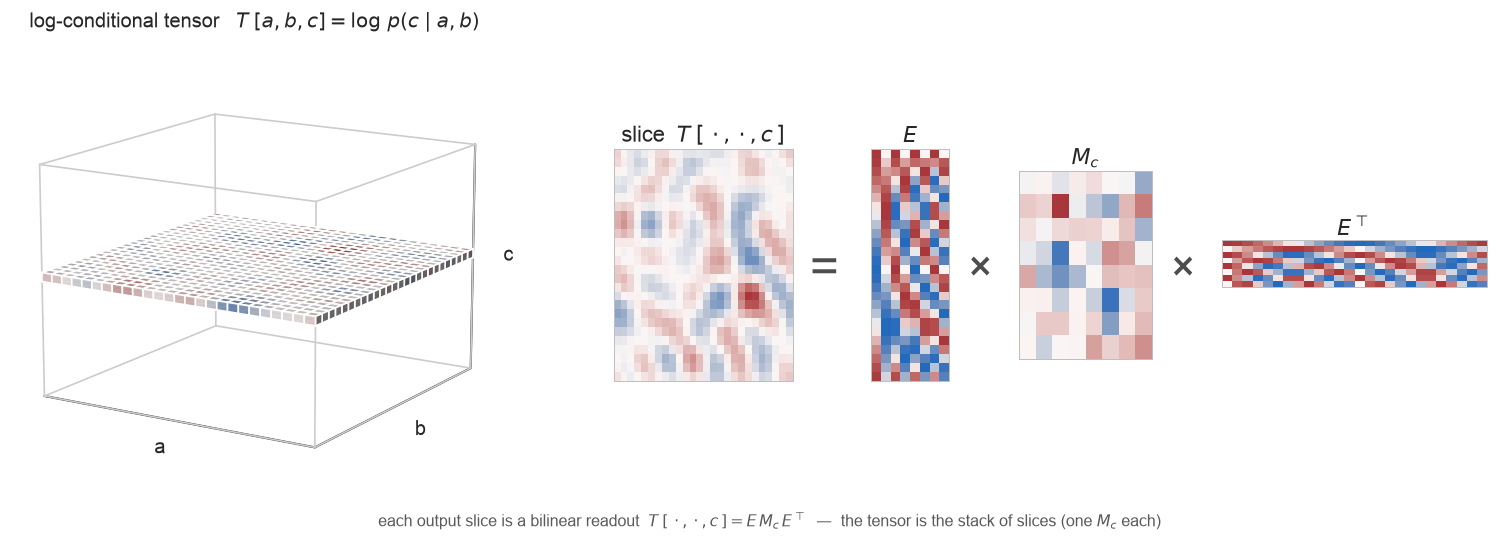

In [13]:
# bilinear hero: one slice of the log-conditional tensor, deconstructed as E · M_c · Eᵀ
import itertools
from matplotlib import cm
from matplotlib.colors import TwoSlopeNorm
n_, nc_, k_ = 26, 26, 8; tok = np.arange(n_); th = 2 * np.pi * tok / n_
Eg = np.stack([f(j * th) for j in range(1, k_ // 2 + 1) for f in (np.cos, np.sin)], 1)   # smooth code
Mg = np.random.default_rng(1).standard_normal((k_, k_, nc_))
T3 = np.einsum("ai,ijc,bj->abc", Eg, Mg, Eg); c0 = 13; sl = T3[:, :, c0]

fig = plt.figure(figsize=(13, 4.6)); fig.set_constrained_layout(False)
axT = fig.add_axes([0.0, 0.05, 0.34, 0.88], projection="3d")
pts = np.array(list(itertools.product([0, n_], [0, n_], [0, nc_])))            # cube outline only
for u, v in [(0,1),(0,2),(0,4),(1,3),(1,5),(2,3),(2,6),(3,7),(4,5),(4,6),(5,7),(6,7)]:
    axT.plot(*zip(pts[u], pts[v]), color="0.8", lw=1.0)
filled = np.zeros(T3.shape, bool); filled[:, :, c0] = True                     # one highlighted slice
fc = np.zeros(T3.shape + (4,))
fc[:, :, c0, :3] = plt.get_cmap("vlag")(TwoSlopeNorm(0, T3.min(), T3.max())(sl))[..., :3]; fc[:, :, c0, 3] = 0.97
axT.voxels(filled, facecolors=fc, edgecolor=None)
axT.set_xlim(0, n_); axT.set_ylim(0, n_); axT.set_zlim(0, nc_)
axT.set_title("log-conditional tensor   $T\\;[a,b,c]=\\log\\,p(c\\mid a,b)$", fontsize=12, pad=-2)
axT.set_xlabel("a", labelpad=-8); axT.set_ylabel("b", labelpad=-8); axT.set_zlabel("c", labelpad=-8)
axT.set_xticks([]); axT.set_yticks([]); axT.set_zticks([])
for pn in (axT.xaxis, axT.yaxis, axT.zaxis):
    pn.pane.set_facecolor((1, 1, 1, 0)); pn.pane.set_edgecolor((1, 1, 1, 0))
axT.view_init(elev=14, azim=-58); axT.text(n_ / 2, n_ / 2, c0 + 1.5, "slice $c$", color="#b03050", fontsize=10)

def _show(ax, A, t, pad=4):
    L = np.abs(A).max(); ax.imshow(A, cmap="vlag", vmin=-L, vmax=L, aspect="auto")
    for s in ax.spines.values():
        s.set_visible(True); s.set_color("0.75"); s.set_linewidth(0.6)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t, fontsize=13, pad=pad)
axS = fig.add_axes([0.40, 0.30, 0.115, 0.42]); _show(axS, sl, "slice  $T\\;[\\,\\cdot,\\cdot,c\\,]$")
axEa = fig.add_axes([0.565, 0.30, 0.05, 0.42]); _show(axEa, Eg, "$E$")
axM = fig.add_axes([0.66, 0.34, 0.085, 0.34]); _show(axM, Mg[:, :, c0], "$M_c$")
axEb = fig.add_axes([0.79, 0.47, 0.17, 0.085]); _show(axEb, Eg.T, "$E^\\top$", pad=2)
fig.text(0.535, 0.5, "=", fontsize=30, ha="center", va="center", color="0.3")
fig.text(0.635, 0.5, "×", fontsize=26, ha="center", va="center", color="0.3")
fig.text(0.765, 0.5, "×", fontsize=26, ha="center", va="center", color="0.3")
fig.text(0.5, 0.035, "each output slice is a bilinear readout  $T\\;[\\,\\cdot,\\cdot,c\\,]=E\\,M_c\\,E^\\top$  —  "
                     "the tensor is the stack of slices (one $M_c$ each)", ha="center", fontsize=9.5, color="0.35")
plt.show()

### The order-2 gallery: factor the conditional

Same recipe as §1, one order up. The latent structure is an **operation**, drawn as a graph (each arrow applies a generator, or the partial order / lattice); the conditional tensor $p(c\mid a,b)$ is its support; factoring that tensor (closed-form, the order-2 analogue of the SVD) gives the embedding. Each row: **operation (as a graph) → conditional tensor → embedding**.

The **group** operations form a 2×2 — {addition, multiplication} × {modular, standard} — plus a product; the remaining rows are **non-group** operations, where the lesson is that the operation's *algebra* picks the geometry.

- **Modular addition** → a **circle**; **standard addition** → an **arc** — the open-boundary version, where the period never closes (the §1 ring-vs-chain split, one order up).
- **Multiplication is addition in disguise.** **Modular multiplication** mod a prime is cyclic — $\times g$ walks through all the units — so it is a **circle ordered by discrete log** (the value labels look scrambled; their *exponents* are in order). **Standard multiplication** is addition of **logs**, so it is the **log number line** (each $\times 2$ is an equal step), arched like standard addition.
- **Product** (two parallel modular additions, mod 14 and mod 9) → a **torus**, one circle per factor.

Non-group operations — the algebra changes, so the geometry changes:

- **Entailment** — the **meet** $a\wedge b=\mathrm{LCA}$ (lowest common ancestor) is an idempotent semilattice → a **hierarchy / tree** embedding.
- **Set intersection** — $a\cap b$ over feature sets is a Boolean lattice → the **hypercube** (one binary coordinate per feature; the cognitive picture of conceptual combination, the feature-based counterpart to entailment's tree).
- **Max** — $\max(a,b)$ on a total order is a chain semilattice → an **ordered line** (the ordinal/magnitude case; same line as addition, different algebra and readout).
- **Averaging** — $\tfrac{a+b}{2}$ is a mean algebra → a **flat (Euclidean) space** (the prototype/blending case; a graded conditional, so its spectrum decays).

Groups give curved, periodic spaces (circles, tori via Fourier); lattices and orders give nested or flat ones — **no inverses, no frequencies**.

The abelian (group) factorizations are **degenerate** — every frequency represents the operation equally well — so the factorization returns a whole family and we display one; *which* is arbitrary (a trained model's rate–margin bias selects it; equivalently the circle is a low-rank phenomenon — the full-rank solution uses all frequencies at once). (A non-abelian *group* needs a matrix-valued code — a block decomposition rather than a plain tensor factorization; omitted here for now.)

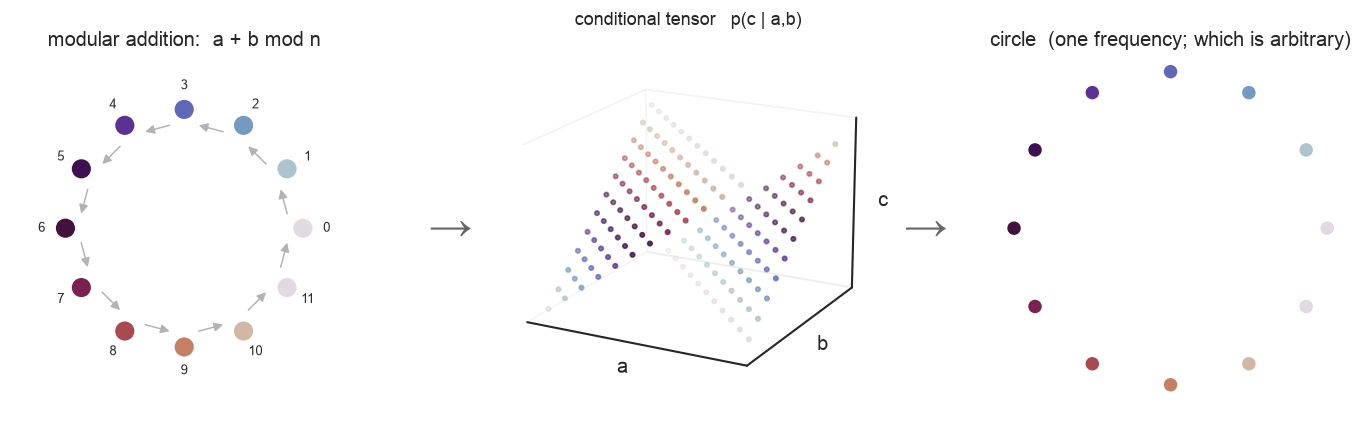

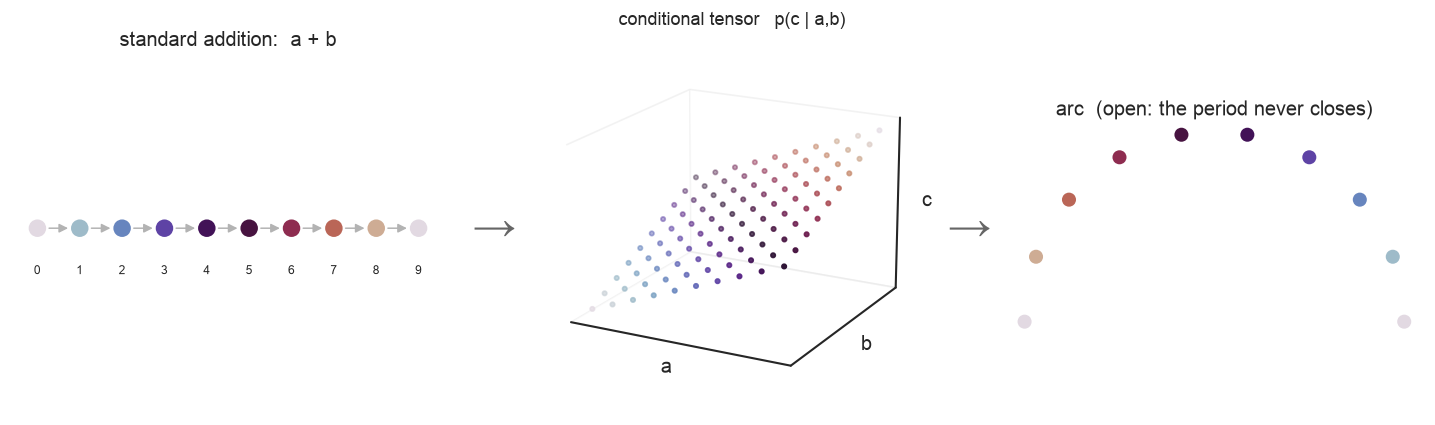

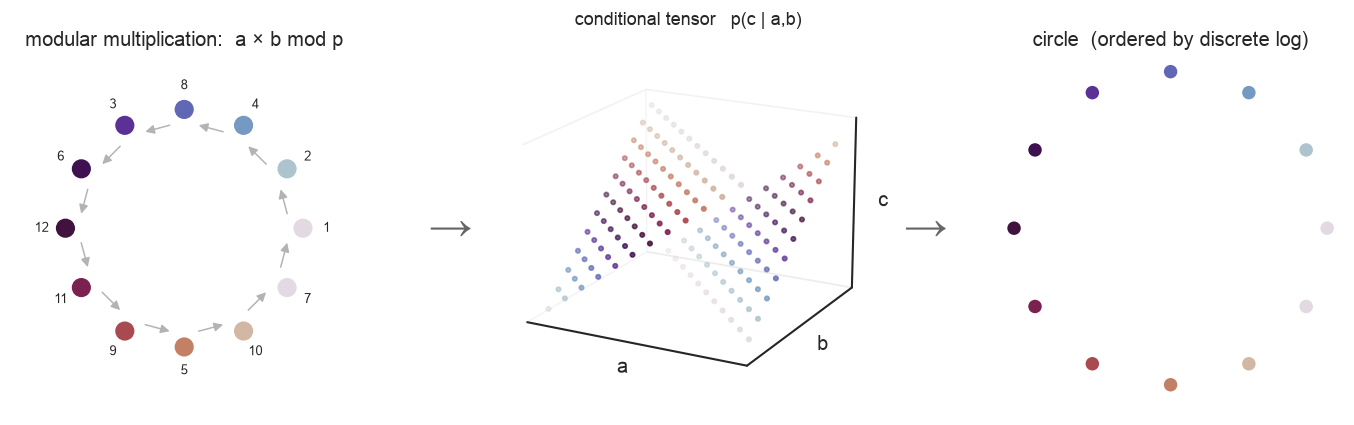

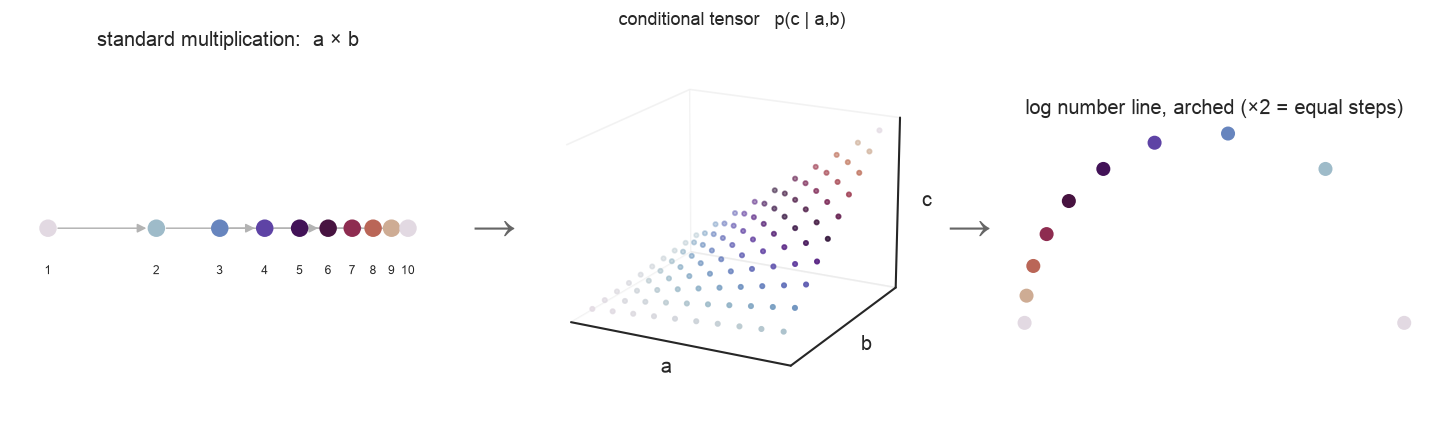

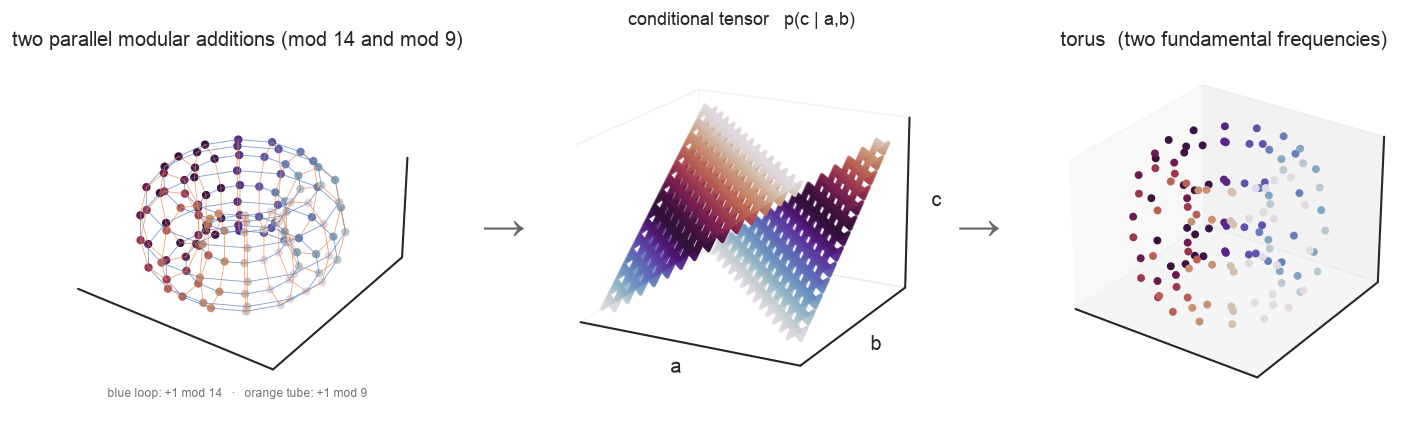

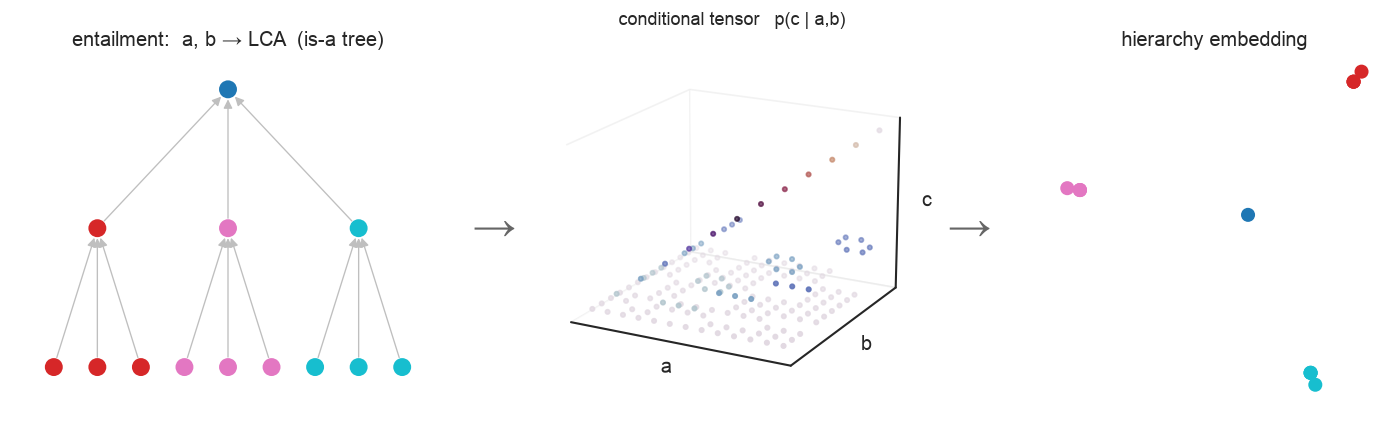

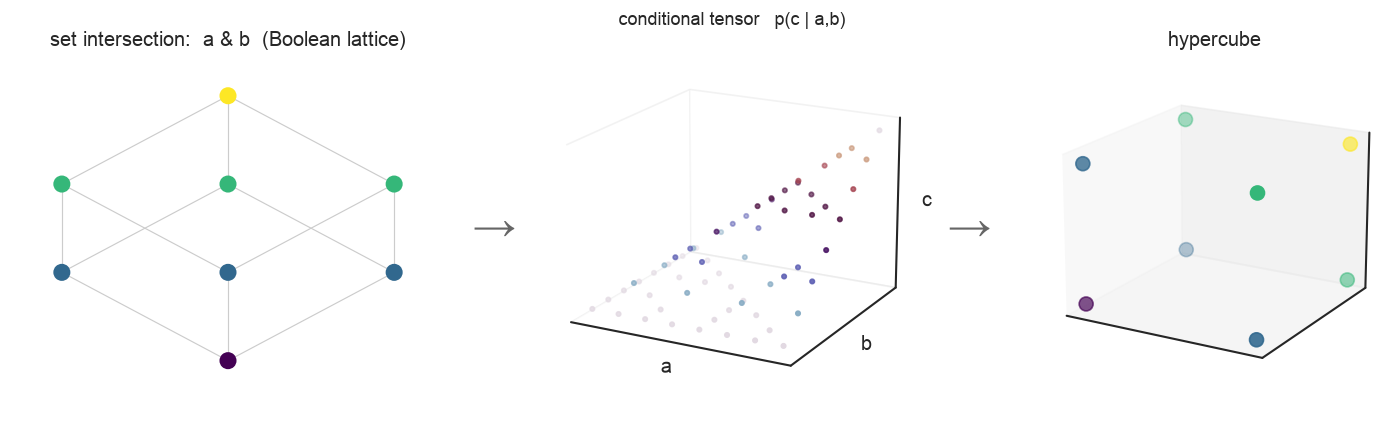

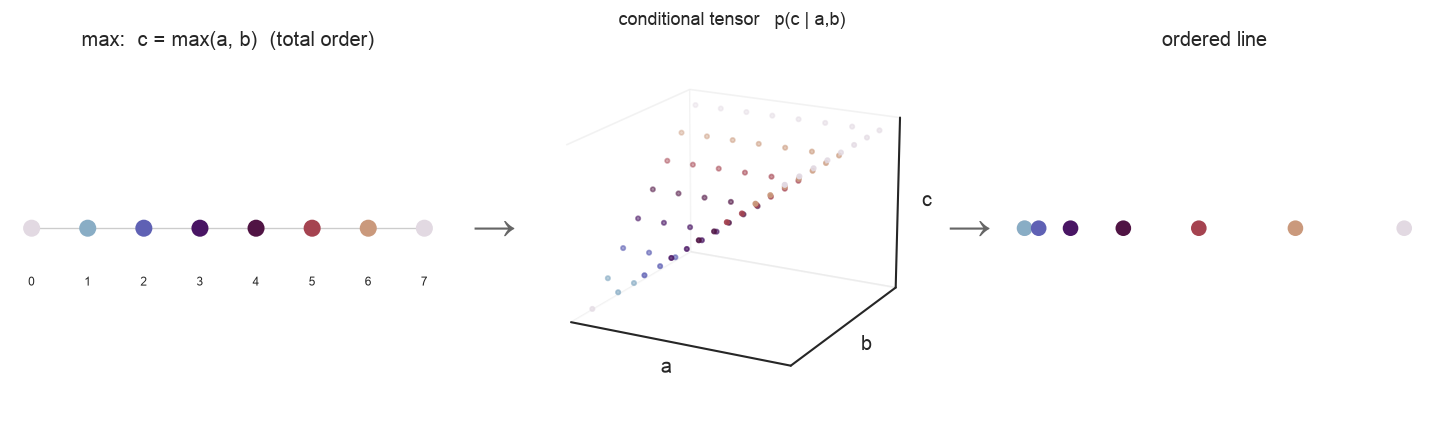

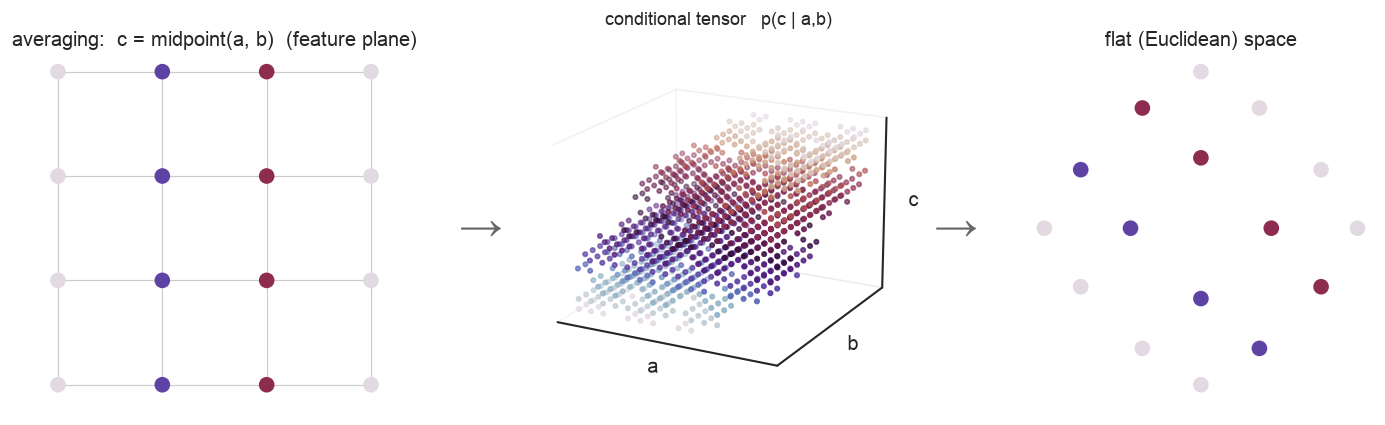

order-2 gallery: groups (add/mult, modular/standard, product) + non-group operations (entailment, intersection, max, averaging)


In [14]:
# ORDER-2 GALLERY: operation as a graph -> conditional tensor -> embedding
def fig3(name, draw_diagram, T, draw_embed, dD=2, dE=2, et="embedding"):
    fig = plt.figure(figsize=(12, 3.5)); fig.set_constrained_layout(False)
    aD = fig.add_axes([0.01, 0.05, 0.30, 0.82], projection="3d" if dD == 3 else None)
    draw_diagram(aD); aD.set_title(name, fontsize=12)
    aT = fig.add_axes([0.375, 0.02, 0.27, 0.90], projection="3d")            # the conditional tensor we factor
    pts = np.argwhere(T > 0); aT.scatter(pts[:, 0], pts[:, 1], pts[:, 2], c=pts[:, 2], cmap="twilight", s=(7 if len(pts) < 2000 else 2))
    aT.set_xlabel("a", labelpad=-10); aT.set_ylabel("b", labelpad=-10); aT.set_zlabel("c", labelpad=-10)
    aT.set_xticks([]); aT.set_yticks([]); aT.set_zticks([]); aT.view_init(elev=18, azim=-62)
    aT.set_title("conditional tensor   p(c | a,b)", fontsize=11)
    for pn in (aT.xaxis, aT.yaxis, aT.zaxis): pn.pane.set_facecolor((1, 1, 1, 0)); pn.pane.set_edgecolor((.9, .9, .9, 1))
    aE = fig.add_axes([0.70, 0.05, 0.29, 0.82], projection="3d" if dE == 3 else None)
    draw_embed(aE); aE.set_title(et, fontsize=12)
    fig.text(0.345, 0.46, "→", fontsize=26, ha="center", va="center", color="0.4")
    fig.text(0.675, 0.46, "→", fontsize=26, ha="center", va="center", color="0.4")
    plt.show()

# (1) modular addition: a clock (each arrow = +1) -> circle.  Degenerate: which frequency is arbitrary
n = 12; th = 2 * np.pi * np.arange(n) / n; pos = np.c_[np.cos(th), np.sin(th)]
T = np.zeros((n, n, n))
for a in range(n):
    for b in range(n): T[a, b, (a + b) % n] = 1
def clock(ax):
    for i in range(n):
        ax.annotate("", xy=pos[(i + 1) % n] * 0.9, xytext=pos[i] * 0.9, arrowprops=dict(arrowstyle="-|>", color="0.7", lw=0.9, shrinkA=9, shrinkB=9))
    ax.scatter(pos[:, 0], pos[:, 1], c=np.arange(n), cmap="twilight", s=110, zorder=3)
    for i in range(n): ax.annotate(str(i), pos[i] * 1.2, ha="center", va="center", fontsize=8)
    ax.set_aspect("equal"); ax.set_xlim(-1.45, 1.45); ax.set_ylim(-1.45, 1.45); _clean2d(ax)
def circ(ax):
    ax.scatter(np.cos(th), np.sin(th), c=np.arange(n), cmap="twilight", s=50); ax.set_aspect("equal"); _clean2d(ax)
fig3("modular addition:  a + b mod n", clock, T, circ, dD=2, dE=2, et="circle  (one frequency; which is arbitrary)")

# (2) standard addition: a number line (+1) -> arc (open: the period never closes)
m = 10; Ta = np.zeros((m, m, 2 * m - 1))
for a in range(m):
    for b in range(m): Ta[a, b, a + b] = 1
def line_add(ax):
    for a in range(m - 1): ax.annotate("", xy=(a + 1, 0), xytext=(a, 0), arrowprops=dict(arrowstyle="-|>", color="0.7", lw=0.9, shrinkA=7, shrinkB=7))
    ax.scatter(range(m), [0] * m, c=range(m), cmap="twilight", s=90, zorder=3)
    for a in range(m): ax.annotate(str(a), (a, -0.16), ha="center", fontsize=7)
    ax.set_xlim(-0.6, m - 0.4); ax.set_ylim(-0.6, 0.6); _clean2d(ax)
ta = np.pi * np.arange(m) / (m - 1)
def arc_add(ax):
    ax.scatter(np.cos(ta), np.sin(ta), c=range(m), cmap="twilight", s=55); ax.set_aspect("equal"); _clean2d(ax)
fig3("standard addition:  a + b", line_add, Ta, arc_add, dD=2, dE=2, et="arc  (open: the period never closes)")

# (3) modular multiplication mod p (prime): x g cycles through the units (cyclic via discrete log) -> circle
p = 13; g = 2; vals = list(range(1, p)); dlog = {}; v = 1
for x in range(p - 1): dlog[v] = x; v = (v * g) % p
ang = {u: 2 * np.pi * dlog[u] / (p - 1) for u in vals}
Tm = np.zeros((p - 1, p - 1, p - 1))                                          # indexed by discrete log = the group order
for a in vals:
    for b in vals: Tm[dlog[a], dlog[b], dlog[(a * b) % p]] = 1
def ring_mult(ax):
    P = {u: np.array([np.cos(ang[u]), np.sin(ang[u])]) for u in vals}
    for u in vals:
        w = (u * g) % p; ax.annotate("", xy=P[w] * 0.9, xytext=P[u] * 0.9, arrowprops=dict(arrowstyle="-|>", color="0.7", lw=0.9, shrinkA=9, shrinkB=9))
    ax.scatter([P[u][0] for u in vals], [P[u][1] for u in vals], c=[dlog[u] for u in vals], cmap="twilight", s=110, zorder=3)
    for u in vals: ax.annotate(str(u), P[u] * 1.2, ha="center", va="center", fontsize=8)
    ax.set_aspect("equal"); ax.set_xlim(-1.45, 1.45); ax.set_ylim(-1.45, 1.45); _clean2d(ax)
def circ_mult(ax):
    ax.scatter([np.cos(ang[u]) for u in vals], [np.sin(ang[u]) for u in vals], c=[dlog[u] for u in vals], cmap="twilight", s=50); ax.set_aspect("equal"); _clean2d(ax)
fig3("modular multiplication:  a × b mod p", ring_mult, Tm, circ_mult, dD=2, dE=2, et="circle  (ordered by discrete log)")

# (4) standard multiplication: log number line (×2 = equal steps) -> log arc
Ts = np.zeros((m, m, m * m))
for a in range(1, m + 1):
    for b in range(1, m + 1): Ts[a - 1, b - 1, a * b - 1] = 1
lx = np.log(np.arange(1, m + 1)); lx = lx / lx.max()
def logline(ax):
    for a in range(1, m + 1):
        if 2 * a <= m: ax.annotate("", xy=(lx[2 * a - 1], 0), xytext=(lx[a - 1], 0), arrowprops=dict(arrowstyle="-|>", color="0.7", lw=0.9, shrinkA=6, shrinkB=6))
    ax.scatter(lx, [0] * m, c=range(m), cmap="twilight", s=90, zorder=3)
    for a in range(1, m + 1): ax.annotate(str(a), (lx[a - 1], -0.16), ha="center", fontsize=7)
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.6, 0.6); _clean2d(ax)
tmu = np.pi * lx
def arc_mult(ax):
    ax.scatter(np.cos(tmu), np.sin(tmu), c=range(m), cmap="twilight", s=55); ax.set_aspect("equal"); _clean2d(ax)
fig3("standard multiplication:  a × b", logline, Ts, arc_mult, dD=2, dE=2, et="log number line, arched (×2 = equal steps)")

# (5) product: two parallel modular additions (mod 14 and mod 9) -> torus
p2, q2 = 14, 9; els = [(i, j) for i in range(p2) for j in range(q2)]; nn = p2 * q2; idx = {e: k for k, e in enumerate(els)}
Tp = np.zeros((nn, nn, nn))
for a in range(nn):
    for b in range(nn): Tp[a, b, idx[((els[a][0] + els[b][0]) % p2, (els[a][1] + els[b][1]) % q2)]] = 1
gx = np.array([e[0] for e in els]); gy = np.array([e[1] for e in els]); t1 = 2 * np.pi * gx / p2; t2 = 2 * np.pi * gy / q2
donut = lambda u, v: np.c_[(2.4 + np.cos(v)) * np.cos(u), (2.4 + np.cos(v)) * np.sin(u), np.sin(v)]
def torus_diagram(ax):                                                 # the operation as a torus: the wrapped grid mesh on a donut
    for j in range(q2):
        u = np.r_[np.arange(p2), 0] * 2 * np.pi / p2; P = donut(u, np.full(p2 + 1, 2 * np.pi * j / q2)); ax.plot(P[:, 0], P[:, 1], P[:, 2], color="#4C72B0", lw=0.5, alpha=0.7)   # +1 mod 14
    for i in range(p2):
        v = np.r_[np.arange(q2), 0] * 2 * np.pi / q2; P = donut(np.full(q2 + 1, 2 * np.pi * i / p2), v); ax.plot(P[:, 0], P[:, 1], P[:, 2], color="#DD8452", lw=0.5, alpha=0.7)   # +1 mod 9
    P = donut(t1, t2); ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=gx, cmap="twilight", s=16, depthshade=False, zorder=5)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=32, azim=-55); ax.set_box_aspect((1, 1, 0.5))
    for pn in (ax.xaxis, ax.yaxis, ax.zaxis): pn.pane.set_facecolor((1, 1, 1, 0)); pn.pane.set_edgecolor((1, 1, 1, 0))
    ax.text2D(0.5, 0.01, "blue loop: +1 mod 14   ·   orange tube: +1 mod 9", transform=ax.transAxes, ha="center", fontsize=7, color="0.45")
def torus(ax):
    P = donut(t1, t2); ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=t1, cmap="twilight", s=14, depthshade=False)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=28, azim=-55)
fig3("two parallel modular additions (mod 14 and mod 9)", torus_diagram, Tp, torus, dD=3, dE=3, et="torus  (two fundamental frequencies)")
# (6) entailment hierarchy — a NON-group operation: the meet  a, b -> LCA (lowest common ancestor) -> a hierarchy embedding
parent = [None]; children = [[]]; depth = [0]; frontier = [0]
for d in range(2):
    new = []
    for u in frontier:
        for _ in range(3):
            i = len(parent); parent.append(u); children.append([]); depth.append(d + 1); children[u].append(i); new.append(i)
    frontier = new
Nn = len(parent); anc = []
for a in range(Nn):
    chain = []; u = a
    while u is not None: chain.append(u); u = parent[u]
    anc.append(chain)
def lca(a, b):
    sa = set(anc[a]); return next(u for u in anc[b] if u in sa)
Te = np.zeros((Nn, Nn, Nn))
for a in range(Nn):
    for b in range(Nn): Te[a, b, lca(a, b)] = 1                              # the meet tensor (output is a node)
def topsub(a):
    u = a
    while parent[u] is not None and depth[u] > 1: u = parent[u]
    return u
cole = np.array([0 if a == 0 else topsub(a) for a in range(Nn)])             # color by top-level subtree
xp = {}; lvs = [a for a in range(Nn) if not children[a]]
for i, lf in enumerate(lvs): xp[lf] = float(i)
def setx(u):
    if children[u]: xp[u] = float(np.mean([setx(c) for c in children[u]]))
    return xp[u]
setx(0); TX = np.array([xp[a] for a in range(Nn)]); TY = -np.array(depth, float)
Me = Te.reshape(Nn, -1); Ue, Se, _ = np.linalg.svd(Me - Me.mean(0), full_matrices=False); Ee = Ue * Se   # factor the meet tensor
def tree_diagram(ax):
    for a in range(Nn):
        if parent[a] is not None: ax.annotate("", xy=(TX[parent[a]], TY[parent[a]]), xytext=(TX[a], TY[a]), arrowprops=dict(arrowstyle="-|>", color="0.75", lw=0.8, shrinkA=6, shrinkB=6))
    ax.scatter(TX, TY, c=cole, cmap="tab10", s=95, zorder=3); ax.margins(0.12); _clean2d(ax)
def hier_embed(ax):
    ax.scatter(Ee[:, 0], Ee[:, 1], c=cole, cmap="tab10", s=55); ax.set_aspect("equal"); _clean2d(ax)
fig3("entailment:  a, b → LCA  (is-a tree)", tree_diagram, Te, hier_embed, dD=2, dE=2, et="hierarchy embedding")
# (7) set intersection — a NON-group lattice: c = a & b over feature sets -> the Boolean cube
nbit = 3; bits = np.array([[(a >> k) & 1 for k in range(nbit)] for a in range(2 ** nbit)], float); Ns = 2 ** nbit
pc = bits.sum(1)
Ti = np.zeros((Ns, Ns, Ns))
for a in range(Ns):
    for b in range(Ns): Ti[a, b, a & b] = 1                                  # meet in the Boolean lattice
def lattice_diagram(ax):                                                     # Hasse diagram: layer by set size
    xp = {}
    for k in range(nbit + 1):
        layer = [a for a in range(Ns) if int(pc[a]) == k]
        for t, a in enumerate(layer): xp[a] = t - (len(layer) - 1) / 2
    for a in range(Ns):
        for b in range(Ns):
            if (a & b) == a and int(pc[b]) == int(pc[a]) + 1: ax.plot([xp[a], xp[b]], [pc[a], pc[b]], color="0.8", lw=0.7, zorder=1)
    ax.scatter([xp[a] for a in range(Ns)], [pc[a] for a in range(Ns)], c=pc, cmap="viridis", s=85, zorder=3); ax.margins(0.15); _clean2d(ax)
def cube_embed(ax):                                                          # factoring is per-feature -> one binary coordinate each
    ax.scatter(bits[:, 0], bits[:, 1], bits[:, 2], c=pc, cmap="viridis", s=70); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18, azim=-60)
fig3("set intersection:  a & b  (Boolean lattice)", lattice_diagram, Ti, cube_embed, dD=2, dE=3, et="hypercube")

# (8) max — a NON-group semilattice on a total order: c = max(a,b) -> an ordered line
nmx = 8; Tx = np.zeros((nmx, nmx, nmx))
for a in range(nmx):
    for b in range(nmx): Tx[a, b, max(a, b)] = 1
Mx = Tx.reshape(nmx, -1); Ux, Sx, _ = np.linalg.svd(Mx - Mx.mean(0), full_matrices=False)
ex = Ux[:, 0] * Sx[0]; ex = ex * np.sign(ex[-1] - ex[0])                     # factor the tensor -> 1-D order, oriented increasing
def order_diagram(ax):
    for a in range(nmx - 1): ax.plot([a, a + 1], [0, 0], color="0.8", lw=0.8, zorder=1)
    ax.scatter(range(nmx), [0] * nmx, c=range(nmx), cmap="twilight", s=85, zorder=3)
    for a in range(nmx): ax.annotate(str(a), (a, -0.2), ha="center", fontsize=7)
    ax.set_ylim(-0.6, 0.6); _clean2d(ax)
def order_embed(ax):
    ax.scatter(ex, [0] * nmx, c=range(nmx), cmap="twilight", s=70); ax.set_ylim(-0.5, 0.5); _clean2d(ax)
fig3("max:  c = max(a, b)  (total order)", order_diagram, Tx, order_embed, dD=2, dE=2, et="ordered line")

# (9) averaging — a NON-group mean algebra: c = midpoint(a,b) -> a flat (Euclidean) feature space
gg = 4; Pg = np.array([(i, j) for i in range(gg) for j in range(gg)], float); Nav = len(Pg); sig = 0.7
Tav = np.zeros((Nav, Nav, Nav))
for a in range(Nav):
    for b in range(Nav):
        w = np.exp(-((Pg - (Pg[a] + Pg[b]) / 2) ** 2).sum(1) / (2 * sig ** 2)); Tav[a, b] = w / w.sum()   # soft midpoint (graded)
Mv = Tav.reshape(Nav, -1); Uv, Sv2, _ = np.linalg.svd(Mv - Mv.mean(0), full_matrices=False); Eav = Uv[:, :2] * Sv2[:2]
def plane_diagram(ax):
    for a in range(Nav):
        for b in range(a + 1, Nav):
            if abs(Pg[a] - Pg[b]).sum() == 1: ax.plot(*zip(Pg[a], Pg[b]), color="0.8", lw=0.7, zorder=1)
    ax.scatter(Pg[:, 0], Pg[:, 1], c=Pg[:, 0], cmap="twilight", s=70, zorder=3); ax.set_aspect("equal"); _clean2d(ax)
def plane_embed(ax):
    ax.scatter(Eav[:, 0], Eav[:, 1], c=Pg[:, 0], cmap="twilight", s=70); ax.set_aspect("equal"); _clean2d(ax)
fig3("averaging:  c = midpoint(a, b)  (feature plane)", plane_diagram, Tav * (Tav > 0.08), plane_embed, dD=2, dE=2, et="flat (Euclidean) space")
print("order-2 gallery: groups (add/mult, modular/standard, product) + non-group operations (entailment, intersection, max, averaging)")